# Sistema de recomendación de películas con MovieLens
**Introducción a la ciencia de datos**

El proyecto evalúa dos tareas con **una sola partición** de los datos:

| Tarea | Pregunta | Qué se compara | Métricas |
|---|---|---|---|
| **1. Predecir la nota** | ¿Qué calificación le dará el usuario a la siguiente película? | Nota predicha contra nota real | RMSE y MAE (en estrellas) |
| **2. Recomendar 10 películas** | ¿La lista de 10 incluye películas que el usuario después vio y le gustaron? | Lista contra las películas escondidas | Hit@10, Precision@10, NDCG@10 |

**Partición:** a cada usuario se le esconden sus **10 calificaciones más recientes**. El modelo nunca las ve: ni para entrenar, ni para calcular promedios, ni para ajustar hiperparámetros.

**Ejecución.** Los datos son `ml-latest-small.zip`, disponible en https://grouplens.org/datasets/movielens/. La carpeta descomprimida `ml-latest-small/` va junto a este notebook y las celdas se ejecutan en orden. Solo se usan numpy, pandas, scipy, scikit-learn y matplotlib (numba es opcional); la ejecución completa tarda entre 3 y 10 minutos.

**Comentarios del código:** cada línea o bloque lleva un comentario (`#`) que dice qué hace.

**Flujo del notebook.** Las secciones siguen las etapas de un proyecto de ciencia de datos:

| Etapa | Secciones | Qué se hace |
|---|---|---|
| **Datos** | 0 | Carga de `ratings.csv` y `movies.csv`, entorno y versiones |
| **Análisis exploratorio** | 1 | Cifras y gráficas que justifican las decisiones posteriores |
| **Preprocesamiento** | 2–3 | Limpieza, variables derivadas y partición sin fuga de información |
| **Evaluación (definición)** | 4 | Métricas de las dos tareas, probadas con casos conocidos |
| **Modelado** | 5–8 | Baselines, k-NN, factorización de matrices (SVD) y modelos por atributos |
| **Evaluación (resultados)** | 9 | Tablas finales, comparación pareada con intervalos de confianza, grupos de usuarios, películas nuevas |
| **Análisis complementario** | 10–11 | Agrupamiento K-means y análisis de errores con un usuario concreto |
| **Conclusiones** | 12 | Respuesta a las preguntas de investigación y limitaciones |

**Reproducibilidad.** Todo lo aleatorio usa la semilla `SEMILLA = 42`; los datos se leen con la ruta relativa `ml-latest-small/`; las figuras del artículo se guardan en `figuras/`; las versiones de las librerías se declaran e imprimen en la sección 0.


## 0. Datos: carga y entorno

**Qué se hace.** Se importan las librerías, se leen las dos tablas que usa el proyecto (`ratings.csv`: quién calificó qué y cuándo; `movies.csv`: título, año y géneros) y se fijan las constantes globales: la semilla, el tamaño de la lista (K = 10) y la paleta de colores.

**Por qué.** Fijar la semilla y leer desde una ruta relativa permite que cualquier persona obtenga exactamente las mismas cifras. `tags.csv` y `links.csv` no se usan: solo 58 usuarios escribieron etiquetas y los identificadores externos no aportan información para estas preguntas.

In [1]:
import os, time                           # os: rutas y carpetas; time: medir cuánto tarda cada paso
import numpy as np                        # numpy: arreglos y operaciones numéricas rápidas
import pandas as pd                       # pandas: tablas (DataFrames) con filas y columnas con nombre
import matplotlib.pyplot as plt           # matplotlib: gráficas
from scipy import sparse                  # scipy.sparse: matrices "dispersas" (guardan solo las celdas con dato)

# Carga de archivos desde la carpeta ml-latest-small, ubicada junto a este notebook (ruta relativa)
RUTA = "ml-latest-small"                                          # carpeta con los CSV de MovieLens
ratings = pd.read_csv(os.path.join(RUTA, "ratings.csv"))   # tabla de calificaciones: userId, movieId, rating, timestamp
movies = pd.read_csv(os.path.join(RUTA, "movies.csv"))     # tabla de películas: movieId, title, genres
print("ratings:", ratings.shape, "| movies:", movies.shape)   # .shape = (número de filas, número de columnas)

SEMILLA = 42                              # semilla fija: todo lo aleatorio sale igual en cada ejecución
K = 10                                    # tamaño de la lista de recomendaciones
COLORES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]   # paleta de las gráficas
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,   # estilo: sin marco
                     "grid.alpha": 0.3, "figure.dpi": 100})                                      # arriba/derecha, cuadrícula tenue
ratings.head()                            # muestra las 5 primeras filas para revisar que cargó bien

ratings: (100836, 4) | movies: (9742, 3)


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


### Entorno y versiones de las librerías

**Por qué.** Los resultados numéricos pueden cambiar ligeramente entre versiones (sobre todo en scikit-learn). Las cifras de este notebook y del artículo se obtuvieron con:

| Librería | Versión |
|---|---|
| Python | 3.12.10 |
| numpy | 2.5.5 |
| pandas | 3.1.1 |
| scipy | 1.18.1 |
| scikit-learn | 1.9.1 |
| matplotlib | 3.11.2 |
| numba | opcional (solo acelera el SVD; no cambia los resultados) |

La celda siguiente imprime las versiones del entorno actual para comprobarlo.

In [2]:
import sys, platform, scipy, sklearn, matplotlib      # módulos cuyas versiones se declaran
print("Python      ", sys.version.split()[0], "|", platform.system())   # versión de Python y sistema operativo
for nombre, mod in [("numpy", np), ("pandas", pd), ("scipy", scipy), ("scikit-learn", sklearn), ("matplotlib", matplotlib)]:
    print(f"{nombre:<12}", mod.__version__)                 # versión de cada librería
print("Semilla:", SEMILLA, "| Carpeta de datos:", RUTA)      # constantes de reproducibilidad
os.makedirs("figuras", exist_ok=True)                        # carpeta relativa para las figuras del artículo

Python       3.12.10 | Windows
numpy        2.5.5
pandas       3.1.1
scipy        1.18.1
scikit-learn 1.9.1
matplotlib   3.11.2
Semilla: 42 | Carpeta de datos: ml-latest-small


## 1. Análisis exploratorio

**Qué se hace.** Se calculan las cifras generales (usuarios, películas, dispersión de la matriz, proporción de notas ≥ 4, calificaciones por usuario y por película) y se grafican tres distribuciones.

**Por qué.** Cada cifra informa una decisión posterior:
- **Dispersión del 98.3 %** → modelos regularizados (sesgos, SVD) y similitudes "encogidas" cuando hay pocos datos en común.
- **Mediana de 3 calificaciones por película** → promedios encogidos hacia la media global, porque el promedio de 1–2 notas no es confiable.
- **El 1 % de películas más calificadas acumula el 15.7 % de las notas** → la popularidad es un baseline obligatorio, y se mide la cobertura y la popularidad de lo recomendado.
- **48 % de notas ≥ 4** → el umbral "le gustó = nota ≥ 4" da clases casi balanceadas.
- **Todos los usuarios tienen ≥ 20 notas** → se pueden esconder 10 por usuario y aún dejar al menos 10 para entrenar.

In [3]:
# Cifras generales de la tabla de calificaciones
n_u, n_m = ratings["userId"].nunique(), ratings["movieId"].nunique()   # nunique = cuántos valores distintos hay
print("Calificaciones:", len(ratings))                                 # len = número de filas
print("Usuarios:", n_u, "| películas con calificación:", n_m, "| películas en movies.csv:", len(movies))
print("Dispersión de la matriz:", round(1 - len(ratings) / (n_u * n_m), 4))   # proporción de celdas vacías
print("Proporción de notas >= 4 ('le gustó'):", round((ratings["rating"] >= 4).mean(), 3))   # media de un True/False = proporción

por_usuario = ratings.groupby("userId").size()      # cuántas calificaciones tiene cada usuario
por_pelicula = ratings.groupby("movieId").size()    # cuántas calificaciones tiene cada película
print("\nCalificaciones por usuario:\n", por_usuario.describe().round(1))    # describe = conteo, media, desviación,
print("\nCalificaciones por película:\n", por_pelicula.describe().round(1))  # mínimo, cuartiles y máximo
print("\nPelículas con menos de 5 calificaciones:", round((por_pelicula < 5).mean(), 3))
print("Películas con una sola calificación:", round((por_pelicula == 1).mean(), 3))
# Qué parte de todas las calificaciones se llevan las películas más populares
top1 = por_pelicula.sort_values(ascending=False).head(int(0.01 * n_m))   # el 1 % de películas con más calificaciones
print("Cuota de calificaciones del 1 % de películas más calificadas:", round(top1.sum() / len(ratings), 3))
print("Duplicados usuario-película:", int(ratings.duplicated(["userId", "movieId"]).sum()))   # mismo usuario y película dos veces
print("Nulos en ratings:", int(ratings.isna().sum().sum()))   # celdas vacías en toda la tabla

Calificaciones: 100836
Usuarios: 610 | películas con calificación: 9724 | películas en movies.csv: 9742
Dispersión de la matriz: 0.983
Proporción de notas >= 4 ('le gustó'): 0.482

Calificaciones por usuario:
 count     610.0
mean      165.3
std       269.5
min        20.0
25%        35.0
50%        70.5
75%       168.0
max      2698.0
dtype: float64

Calificaciones por película:
 count    9724.0
mean       10.4
std        22.4
min         1.0
25%         1.0
50%         3.0
75%         9.0
max       329.0
dtype: float64

Películas con menos de 5 calificaciones: 0.625
Películas con una sola calificación: 0.354
Cuota de calificaciones del 1 % de películas más calificadas: 0.157
Duplicados usuario-película: 0
Nulos en ratings: 0


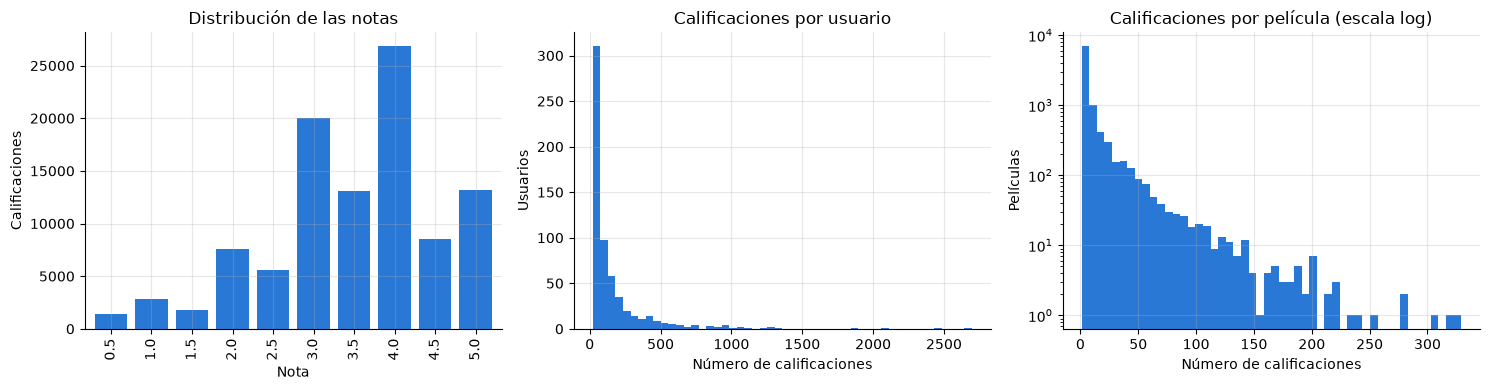

In [4]:
# Tres gráficas lado a lado
fig, ax = plt.subplots(1, 3, figsize=(15, 4))       # 1 fila y 3 columnas de gráficas; ax[0], ax[1], ax[2]
ratings["rating"].value_counts().sort_index().plot.bar(ax=ax[0], color=COLORES[0], width=0.8)   # cuántas veces aparece cada nota
ax[0].set_title("Distribución de las notas"); ax[0].set_xlabel("Nota"); ax[0].set_ylabel("Calificaciones")
ax[1].hist(por_usuario, bins=50, color=COLORES[0])  # histograma: agrupa a los usuarios en 50 intervalos
ax[1].set_title("Calificaciones por usuario"); ax[1].set_xlabel("Número de calificaciones"); ax[1].set_ylabel("Usuarios")
ax[2].hist(por_pelicula, bins=50, color=COLORES[0], log=True)   # log=True: eje vertical en escala logarítmica
ax[2].set_title("Calificaciones por película (escala log)"); ax[2].set_xlabel("Número de calificaciones"); ax[2].set_ylabel("Películas")
plt.tight_layout(); fig.savefig("figuras/fig_exploracion.png", dpi=200, bbox_inches="tight"); plt.show()                      # ajusta márgenes y dibuja

**1. Distribución de las notas (izquierda).** Cada barra es una nota posible (0.5, 1, 1.5, … 5) y su altura es cuántas veces se dio esa nota. Las barras altas están entre 3 y 5 y las notas bajas son raras: la gente tiende a calificar películas que eligió ver, y uno suele elegir lo que cree que le va a gustar. También se ve que las notas enteras (3, 4, 5) son más comunes que las medias (3.5, 4.5).
*Por qué importa:* si casi todas las notas están entre 3 y 5, un modelo que siempre diga "3.5" ya falla poco. Por eso no basta con que un modelo tenga un error pequeño: hay que compararlo con baselines tan simples como ese (sección 5).

**2. Calificaciones por usuario (centro).** Es un **histograma**: el eje horizontal se divide en intervalos (por ejemplo, "de 20 a 74 calificaciones") y la altura de cada barra es cuántos usuarios caen en ese intervalo. Hay una barra muy alta a la izquierda y una "cola" larga y baja hacia la derecha: la mayoría calificó pocas películas (el mínimo es 20) y unos cuantos calificaron cientos o miles. A esa forma se le llama **distribución sesgada a la derecha**.
*Por qué importa:* los usuarios con pocas calificaciones son los más difíciles de recomendar porque se sabe poco de ellos. La sección 9.4 compara los modelos justamente por este número.

**3. Calificaciones por película (derecha).** Igual que la anterior, pero por película y con el eje vertical en **escala logarítmica**: cada marca del eje vale 10 veces la anterior (1, 10, 100, 1000). Se usa porque la primera barra es tan alta que, en escala normal, las demás no se verían. La gran mayoría de las películas tiene muy pocas calificaciones (el 35.4 % solo una) y unas pocas tienen cientos. A esto se le llama **cola larga**: pocos éxitos concentran gran parte de la atención y miles de películas casi nadie las ve.
*Por qué importa:* de una película con una sola nota no se puede saber si es buena. Esto obliga a "encoger" sus promedios (sección 5) y explica por qué recomendar lo más popular es un rival difícil.

**Dos cifras clave de la celda anterior:** la **dispersión** es la proporción de celdas vacías de la tabla usuarios × películas; con 0.983, el 98.3 % de las combinaciones no tiene nota. La **cuota del 1 % más calificado** es 0.157: ese 1 % de películas acumula el 15.7 % de todas las calificaciones.

## 2. Preprocesamiento: limpieza y preparación

**Qué se hace.** Se eliminan pares usuario-película duplicados, se convierte la marca de tiempo a fecha, se extrae el año del título con una expresión regular, se convierten los géneros (separados por "|") en 19 indicadores 0/1 y se renumeran usuarios y películas con índices consecutivos para construir matrices.

**Por qué.** Los modelos necesitan variables numéricas y una matriz usuarios × películas; el año y los géneros son la única información de contenido disponible para películas sin calificaciones (arranque en frío). A los títulos sin año se les asigna la mediana, para no perder esas películas.

In [5]:
ratings = ratings.drop_duplicates(["userId", "movieId"]).copy()        # quita pares usuario-película repetidos
ratings["fecha"] = pd.to_datetime(ratings["timestamp"], unit="s")      # segundos desde 1970 → fecha legible
ratings["gusto"] = (ratings["rating"] >= 4).astype(int)                # "le gustó" = 1 si la nota es 4 o más, si no 0

# Año y géneros de cada película
movies["anio"] = movies["title"].str.extract(r"\((\d{4})\)\s*$")[0].astype(float)   # 4 dígitos entre paréntesis al final del título
generos = movies.set_index("movieId")["genres"].str.get_dummies("|").drop(columns="(no genres listed)", errors="ignore")  # una columna 0/1 por género
print("Títulos sin año extraíble:", int(movies["anio"].isna().sum()))
print("Películas sin géneros:", int((movies["genres"] == "(no genres listed)").sum()))
print("Géneros distintos:", generos.shape[1])

# Índices 0..n-1 para usuarios y películas (filas y columnas de las matrices)
usuarios_ids = np.sort(ratings["userId"].unique())          # lista ordenada de userId
peliculas_ids = np.sort(ratings["movieId"].unique())        # lista ordenada de movieId que tienen alguna nota
fila_de = pd.Series(np.arange(len(usuarios_ids)), index=usuarios_ids)   # traductor: userId → número de fila
col_de = pd.Series(np.arange(len(peliculas_ids)), index=peliculas_ids)  # traductor: movieId → número de columna
NU, NI = len(usuarios_ids), len(peliculas_ids)              # número de usuarios y de películas
ratings["u"] = fila_de[ratings["userId"]].to_numpy()        # cada calificación con su número de fila
ratings["i"] = col_de[ratings["movieId"]].to_numpy()        # y su número de columna
titulo = movies.set_index("movieId")["title"]               # para buscar el título a partir del movieId
print("Matriz:", NU, "usuarios x", NI, "películas")

Títulos sin año extraíble: 13
Películas sin géneros: 34
Géneros distintos: 19
Matriz: 610 usuarios x 9724 películas


**Resultado de la limpieza.** 13 títulos no tienen año extraíble (se les asigna la mediana más adelante) y 34 películas no tienen género (todas sus columnas de género quedan en 0). "Matriz" indica el tamaño de la tabla usuarios × películas sobre la que trabajan los modelos: 610 × 9,724.

## 3. Preprocesamiento: partición sin fuga de información

**Qué se hace y por qué.** Se simula el uso real del sistema: con lo que el usuario calificó antes, ¿se puede anticipar lo que calificará después? Por eso se esconden sus calificaciones **más recientes**, no unas al azar (eso dejaría usar el futuro para predecir el pasado).

| Conjunto | Qué contiene | Para qué |
|---|---|---|
| `test` | Las **10 calificaciones más recientes** de cada usuario | Evaluación final (se usa una sola vez) |
| `train` | Todo lo anterior | Entrenar los modelos finales |
| `valid` | Las 5 más recientes **dentro de** `train` | Elegir hiperparámetros |
| `ajuste` | `train` sin `valid` | Entrenar mientras se eligen hiperparámetros |

Un **hiperparámetro** es una decisión que se fija antes de entrenar (por ejemplo, cuántos vecinos usa un k-NN). Si se eligiera mirando `test`, el resultado final sería optimista: el modelo estaría "hecho a la medida" del examen. Por eso se elige con `valid`, que funciona como un examen de práctica.

El orden es por fecha; los empates (muchos usuarios calificaron varias películas en el mismo segundo) se rompen por `movieId` para que el resultado sea reproducible.

**Limitación:** el corte es por usuario. El entrenamiento puede contener calificaciones de *otros* usuarios hechas después de la prueba de un usuario dado. Es la práctica habitual ("leave-last-out"), pero no es un corte temporal global.

In [6]:
N_PRUEBA, N_VALID = 10, 5                                   # cuántas se esconden para prueba y para validación
# Partición: contar hacia atrás desde la calificación más reciente de cada usuario
ratings = ratings.sort_values(["userId", "timestamp", "movieId"]).reset_index(drop=True)   # por usuario y por fecha
ratings["desde_final"] = ratings.groupby("userId").cumcount(ascending=False)   # 0 = la más reciente, 1 = la anterior...

test = ratings[ratings["desde_final"] < N_PRUEBA].copy()                  # posiciones 0..9 desde el final
train = ratings[ratings["desde_final"] >= N_PRUEBA].copy()                # todo lo demás
valid = train[train["desde_final"] < N_PRUEBA + N_VALID].copy()           # posiciones 10..14: las 5 últimas de train
ajuste = train[train["desde_final"] >= N_PRUEBA + N_VALID].copy()         # train sin esas 5

n_train_u = train.groupby("u").size().reindex(range(NU), fill_value=0)   # calificaciones de cada usuario en train
print("train:", len(train), "| test:", len(test), "| ajuste:", len(ajuste), "| valid:", len(valid))
print("Calificaciones en train por usuario (mín, mediana, máx):", n_train_u.min(), n_train_u.median(), n_train_u.max())
print("Usuarios con al menos una película que 'le gustó' en test:", int((test.groupby("u")["gusto"].sum() > 0).sum()), "de", NU)
print("Calificaciones de test sobre películas que NO están en train:", round((~test["i"].isin(train["i"])).mean(), 3))   # ~ = "no"
print("Calificaciones de test con la misma fecha que la última de train:",
      round((test.groupby("u")["timestamp"].min() == train.groupby("u")["timestamp"].max()).mean(), 3), "de los usuarios")

train: 94736 | test: 6100 | ajuste: 91686 | valid: 3050
Calificaciones en train por usuario (mín, mediana, máx): 10 60.5 2688
Usuarios con al menos una película que 'le gustó' en test: 576 de 610
Calificaciones de test sobre películas que NO están en train: 0.033
Calificaciones de test con la misma fecha que la última de train: 0.17 de los usuarios


In [7]:
# Verificaciones: si alguna falla, la partición tiene un error
for h, o, nombre in [(train, test, "train/test"), (ajuste, valid, "ajuste/valid")]:      # revisa los dos cortes
    assert len(h.merge(o, on=["u", "i"])) == 0, f"{nombre}: hay pares usuario-película repetidos"   # ningún par en ambos lados
    assert (h.groupby("u")["timestamp"].max() <= o.groupby("u")["timestamp"].min()).all(), f"{nombre}: hay prueba anterior al entrenamiento"
assert (test.groupby("u").size() == N_PRUEBA).all() and (valid.groupby("u").size() == N_VALID).all()   # 10 y 5 por usuario
assert set(train["u"]) == set(range(NU)), "Algún usuario se quedó sin entrenamiento"
print("Verificaciones superadas.")

u0 = 0                                                      # revisión a mano con el primer usuario
print(f"\nUsuario {usuarios_ids[u0]}: train de {train[train.u == u0]['fecha'].min().date()} a {train[train.u == u0]['fecha'].max().date()}"
      f" | test de {test[test.u == u0]['fecha'].min().date()} a {test[test.u == u0]['fecha'].max().date()}")

Verificaciones superadas.

Usuario 1: train de 2000-07-30 a 2000-07-30 | test de 2000-07-30 a 2000-08-08


**Qué muestran estas dos celdas**
- **Tamaños:** `test` tiene 6,100 filas (610 usuarios × 10) y `valid` 3,050 (610 × 5).
- **Usuarios con al menos una película que le gustó en test:** 576 de 610. Solo esos cuentan para las métricas de lista que usan "le gustó"; los otros 34 no tienen nada que acertar.
- **Películas de test que no están en train (3.3 %):** son películas que el sistema nunca ha visto calificadas ("películas nuevas"). Ningún modelo de historial puede saber nada de ellas; la sección 9.5 las analiza aparte.
- **Misma fecha que la última de train (17 % de los usuarios):** usuarios cuya prueba empieza en el mismo segundo en que terminó su entrenamiento. Pasa cuando alguien calificó muchas películas de golpe en una sesión; el corte cae a mitad de esa sesión y la "siguiente película" no es realmente futura. Es una limitación del estudio.
- **"Verificaciones superadas"** significa que ninguna calificación escondida se coló en el entrenamiento. Un `AssertionError` indicaría un error en la partición.

## 4. Evaluación: definición de las métricas

**Por qué se definen antes de los modelos.** Todos los modelos producen una matriz de puntajes usuarios × películas y se evalúan con **la misma función** (`evaluar`), sobre los mismos usuarios y las mismas películas escondidas. Así la comparación es justa. Las funciones se prueban con casos de resultado conocido antes de usarlas.

**Tarea 1 (nota):**
- **Error** de una predicción = nota predicha − nota real. Si el modelo dice 3.5 y el usuario puso 4, el error es −0.5.
- **MAE** (error absoluto medio): el promedio de los errores sin signo. Un MAE de 0.7 significa que en promedio el modelo falla por 0.7 estrellas.
- **RMSE** (raíz del error cuadrático medio): se elevan los errores al cuadrado, se promedian y se saca raíz. Se lee también en estrellas, pero castiga más los errores grandes: fallar una vez por 3 estrellas pesa más que fallar tres veces por 1. Siempre es mayor o igual que el MAE.
- Las predicciones se recortan al rango 0.5–5, porque no existen notas fuera de ese rango.

**Tarea 2 (lista de 10):** se recomienda entre las películas que el sistema conoce (las que aparecen en el conjunto de entrenamiento), quitando las que el usuario ya calificó.
- **Hit@10 (le gustó):** proporción de usuarios cuya lista incluye al menos una película escondida con nota ≥ 4. Es la métrica de la idea original.
- **Hit@10 (cualquiera):** lo mismo, pero vale cualquier película escondida, sin importar la nota ("acertó que la vería").
- **Precision@10:** de las 10 recomendadas, qué proporción eran escondidas con nota ≥ 4. Con 1 acierto vale 0.1.
- **NDCG@10 (principal):** premia tener aciertos y tenerlos arriba de la lista. 1 = perfecto, 0 = ningún acierto.
- **Cobertura:** proporción del catálogo que aparece en al menos una lista. Si todos reciben la misma lista, la cobertura es mínima.
- **Popularidad media:** número medio de calificaciones (en entrenamiento) de las películas recomendadas. Sirve para ver si un modelo recomienda solo éxitos o solo rarezas.

Las métricas de lista que dependen de "le gustó" se promedian solo sobre usuarios con al menos una película escondida con nota ≥ 4.

In [8]:
# NDCG@10: qué tan bien ordenada está la lista
def ndcg_at_k(lista, relevantes, k=K):
    """lista: películas recomendadas en orden. relevantes: conjunto de películas que sí le gustaron."""
    dcg = sum(1 / np.log2(p + 2) for p, m in enumerate(lista[:k]) if m in relevantes)   # puntos por cada acierto, menos si está abajo
    ideal = sum(1 / np.log2(p + 2) for p in range(min(len(relevantes), k)))             # los puntos de la lista perfecta
    return dcg / ideal if ideal > 0 else 0.0                                            # proporción entre 0 y 1

# Pruebas con casos conocidos: si alguna falla, hay un error en la función.
assert abs(ndcg_at_k([1, 2, 3], {1, 2, 3}) - 1) < 1e-9                     # lista perfecta = 1
assert ndcg_at_k([4, 5, 6], {1, 2, 3}) == 0                                 # ningún acierto = 0
arriba = ndcg_at_k([1] + list(range(100, 109)), {1})                        # el acierto en 1.er lugar
abajo = ndcg_at_k(list(range(100, 109)) + [1], {1})                         # el mismo acierto en 10.º lugar
assert abs(arriba - 1) < 1e-9 and abs(abajo - 1 / np.log2(11)) < 1e-9 and arriba > abajo
print("Pruebas de NDCG@10 superadas: acierto arriba =", round(arriba, 3), "| acierto abajo =", round(abajo, 3))

# Las k películas con mayor puntaje para cada usuario
def top_k(P, hist, k=K):
    """Las k películas con mayor puntaje para cada usuario, sin las ya vistas y solo del catálogo de hist."""
    S = np.array(P, dtype=np.float64)                         # copia de los puntajes (no se modifica P)
    fuera = np.ones(NI, dtype=bool); fuera[hist["i"].unique()] = False   # True = película que no está en hist
    S[:, fuera] = -np.inf                                     # -infinito: nunca quedará entre las mejores
    S[hist["u"].to_numpy(), hist["i"].to_numpy()] = -np.inf   # tampoco lo que el usuario ya calificó
    idx = np.argpartition(-S, k, axis=1)[:, :k]               # las k mayores de cada fila, aún sin ordenar
    orden = np.argsort(-np.take_along_axis(S, idx, axis=1), axis=1, kind="stable")   # orden de mayor a menor
    return np.take_along_axis(idx, orden, axis=1)             # matriz usuarios × k con las columnas recomendadas

# Calcula todas las métricas de un modelo
def evaluar(P, hist, obj, nota=True, lista=True, k=K):
    """P: matriz (usuarios x películas) de puntajes. Devuelve métricas globales y por usuario."""
    r = {}                                                    # diccionario de resultados
    if nota:                                                  # --- tarea 1 ---
        pred = np.clip(P[obj["u"].to_numpy(), obj["i"].to_numpy()], 0.5, 5)   # nota predicha de cada par escondido
        err = pred - obj["rating"].to_numpy()                 # error de cada predicción
        r["RMSE"], r["MAE"] = np.sqrt(np.mean(err ** 2)), np.mean(np.abs(err))
        r["_err"] = err                                       # se guardan para análisis posteriores (9.4 y 9.5)
        r["_mse_u"] = pd.Series(err ** 2).groupby(obj["u"].to_numpy()).mean().reindex(range(NU)).to_numpy()   # error por usuario
    if lista:                                                 # --- tarea 2 ---
        tops = top_k(P, hist, k)                              # la lista de cada usuario
        gusta = obj[obj["gusto"] == 1].groupby("u")["i"].apply(set)   # escondidas que le gustaron, por usuario
        todas = obj.groupby("u")["i"].apply(set)                       # todas las escondidas, por usuario
        nd, hg, pr, ha = (np.full(NU, np.nan) for _ in range(4))       # un valor por usuario; NaN = no aplica
        for u in range(NU):
            l = tops[u]
            ha[u] = len(set(l) & todas.get(u, set())) > 0              # ¿acertó alguna escondida? (& = intersección)
            rel = gusta.get(u)
            if rel:                                                    # solo si le gustó alguna escondida
                nd[u], hg[u], pr[u] = ndcg_at_k(l, rel, k), len(set(l) & rel) > 0, len(set(l) & rel) / k
        conteo = np.bincount(hist["i"], minlength=NI)                  # calificaciones de cada película en hist
        r.update({"Hit@10 (le gustó)": np.nanmean(hg), "Hit@10 (cualquiera)": np.nanmean(ha),   # nanmean ignora los NaN
                  "Precision@10": np.nanmean(pr), "NDCG@10": np.nanmean(nd),
                  "Cobertura": len(np.unique(tops)) / hist["i"].nunique(),
                  "Popularidad media": conteo[tops].mean(), "_ndcg_u": nd, "_tops": tops})
    return r

# Convierte el diccionario de resultados en una tabla
def tabla(res, columnas=None):
    filas = {n: {c: v for c, v in d.items() if not c.startswith("_")} for n, d in res.items()}   # sin las claves internas "_"
    t = pd.DataFrame(filas).T                                 # .T = transponer: un modelo por fila
    return t[[c for c in (columnas or t.columns) if c in t.columns]]

COL_NOTA = ["RMSE", "MAE"]                                    # columnas de la tarea 1
COL_LISTA = ["NDCG@10", "Hit@10 (le gustó)", "Hit@10 (cualquiera)", "Precision@10", "Cobertura", "Popularidad media"]
resultados = {}                                               # aquí se acumulan los resultados en test de todos los modelos
print("Funciones de evaluación listas.")

Pruebas de NDCG@10 superadas: acierto arriba = 1.0 | acierto abajo = 0.289
Funciones de evaluación listas.


**Prueba de la métrica.** Se obtiene *acierto arriba = 1.0* y *acierto abajo = 0.289*: una lista con su único acierto en primer lugar obtiene la nota máxima, y la misma lista con el acierto en décimo lugar obtiene menos de un tercio. NDCG castiga que lo bueno quede abajo, porque en una app el usuario mira primero lo de arriba.

## 5. Modelado: líneas base (baselines)

Un **baseline** (línea base) es un método deliberadamente simple que sirve de vara de medir: si un modelo complicado no le gana, no vale la pena.

| Baseline | Tarea 1 | Tarea 2 | Idea |
|---|---|---|---|
| Aleatorio | — | ✓ | Piso absoluto de la lista |
| Promedio global | ✓ | — | La misma nota para todo |
| Promedio del usuario | ✓ | — | Cada usuario tiene su "nota típica" (no sirve para ordenar: da lo mismo a todas sus películas) |
| Promedio de la película | ✓ | ✓ | Cada película tiene su "nota típica" |
| Sesgos usuario + película | ✓ | ✓ | promedio global + desviación del usuario + desviación de la película, regularizados. Suele ser muy difícil de superar en la tarea 1 |
| Más calificadas | — | ✓ | Recomienda lo más popular a todos |
| Mejor promedio ajustado | — | ✓ | Promedio de la película encogido hacia el promedio global para no confiar en películas con pocas notas |

Todos se calculan **solo con el conjunto de entrenamiento** que reciben (`hist`).

In [9]:
# Modelo de sesgos: nota ≈ promedio global + sesgo del usuario + sesgo de la película
def sesgos(hist, reg_u=15, reg_i=10, n_iter=10):
    """Promedio global + sesgo de usuario + sesgo de película (mínimos cuadrados regularizados, alternando)."""
    u, i, r = hist["u"].to_numpy(), hist["i"].to_numpy(), hist["rating"].to_numpy()   # columnas como arreglos
    mu = r.mean(); bu = np.zeros(NU); bi = np.zeros(NI)        # empiezan en 0
    for _ in range(n_iter):                                    # 10 rondas: cada una mejora a la otra
        bu = np.bincount(u, r - mu - bi[i], NU) / (np.bincount(u, minlength=NU) + reg_u)   # sesgo de cada usuario
        bi = np.bincount(i, r - mu - bu[u], NI) / (np.bincount(i, minlength=NI) + reg_i)   # sesgo de cada película
    return mu, bu, bi

# Cada función pred_* devuelve una matriz usuarios × películas con un puntaje para cada par
def pred_media_global(hist):
    return np.full((NU, NI), hist["rating"].mean())            # el mismo número en todas las celdas

def pred_media_usuario(hist):
    m = hist.groupby("u")["rating"].mean().reindex(range(NU), fill_value=hist["rating"].mean()).to_numpy()   # promedio de cada usuario
    return np.repeat(m[:, None], NI, axis=1)                   # se copia a todas sus películas

# Promedio de cada película, encogido hacia el promedio global
def media_pelicula(hist, m=0):
    """Promedio de cada película encogido hacia el promedio global con peso m (m=0: promedio simple)."""
    mu = hist["rating"].mean()
    s = np.bincount(hist["i"], hist["rating"], NI); n = np.bincount(hist["i"], minlength=NI)   # suma y número de notas
    return np.where(n + m > 0, (s + m * mu) / np.maximum(n + m, 1e-12), mu)                     # sin notas → promedio global

def pred_media_pelicula(hist):
    return np.repeat(media_pelicula(hist)[None, :], NU, axis=0)   # el mismo promedio para todos los usuarios

def pred_sesgos(hist):
    mu, bu, bi = sesgos(hist)
    return mu + bu[:, None] + bi[None, :]                      # suma para cada par usuario-película

def pred_mas_calificadas(hist):
    return np.repeat(np.bincount(hist["i"], minlength=NI)[None, :].astype(float), NU, axis=0)   # puntaje = número de notas

def pred_promedio_ajustado(hist, m=10):
    return np.repeat(media_pelicula(hist, m)[None, :], NU, axis=0)   # m = 10: como si tuviera 10 notas extra iguales al promedio

def pred_aleatorio(hist):
    return np.random.default_rng(SEMILLA).random((NU, NI))     # puntajes al azar

# Se evalúa cada baseline en test
baselines = [("Aleatorio", pred_aleatorio, False, True),       # (nombre, función, ¿tarea 1?, ¿tarea 2?)
             ("Promedio global", pred_media_global, True, False),
             ("Promedio del usuario", pred_media_usuario, True, False),
             ("Promedio de la película", pred_media_pelicula, True, True),
             ("Sesgos usuario + película", pred_sesgos, True, True),
             ("Más calificadas", pred_mas_calificadas, False, True),
             ("Mejor promedio ajustado", pred_promedio_ajustado, False, True)]
for nombre, f, nota, lista in baselines:
    resultados[nombre] = evaluar(f(train), train, test, nota=nota, lista=lista)   # se entrena con train y se evalúa en test
tabla(resultados, COL_NOTA + COL_LISTA).round(3)

,RMSE,MAE,NDCG@10,Hit@10 (le gustó),Hit@10 (cualquiera),Precision@10,Cobertura,Popularidad media
Aleatorio,NaN,NaN,0.001,0.007,0.008,0.001,0.476,8.886
Promedio global,1.101,0.897,NaN,NaN,NaN,NaN,NaN,NaN
Promedio del usuario,1.022,0.785,NaN,NaN,NaN,NaN,NaN,NaN
Promedio de la película,1.040,0.811,0.000,0.000,0.000,0.000,0.026,1.034
Sesgos usuario + película,0.944,0.724,0.031,0.165,0.180,0.020,0.008,136.426
Más calificadas,NaN,NaN,0.054,0.247,0.275,0.037,0.013,220.029
Mejor promedio ajustado,NaN,NaN,0.040,0.189,0.202,0.027,0.007,150.393


Cada fila es un método y cada columna una métrica. `NaN` (*Not a Number*, "no es un número") significa que ese método no hace esa tarea.

**Columnas RMSE y MAE (tarea 1, menor es mejor).** *Promedio global* falla por 1.10 estrellas (RMSE); los promedios por usuario (1.02) y por película (1.04) mejoran un poco, y *Sesgos usuario + película* es el mejor de los cuatro (0.944). Combinar "este usuario es generoso" con "esta película suele gustar" captura buena parte de lo que se puede predecir. **Esa fila es la referencia para la tarea 1.**

**Columna NDCG@10 y las Hit (tarea 2, mayor es mejor).**
- *Aleatorio* da casi 0 (0.001): con miles de películas posibles y 10 escondidas por usuario, una lista al azar casi nunca acierta.
- *Más calificadas* es el mejor baseline de lista (0.054). No es que lo popular le guste a todos, sino que lo popular es lo que más gente termina viendo, y por lo tanto calificando. **Esa fila es la referencia para la tarea 2.**
- *Promedio de la película* queda en 0, aunque suene razonable. El "mejor promedio" lo tienen películas con una sola nota de 5 que casi nadie ve; la columna *Popularidad media* lo confirma: sus películas recomendadas tienen en promedio 1 calificación. Es la trampa de la cola larga.
- *Mejor promedio ajustado* corrige parte de esa trampa (0.040): al "encoger" los promedios, una película necesita muchas notas altas para quedar arriba.

**Hit@10 (le gustó) contra Hit@10 (cualquiera).** La segunda siempre es mayor o igual, porque cuenta también aciertos con películas que el usuario vio pero calificó bajo. El 0.247 de *Más calificadas* significa que al 24.7 % de los usuarios se le recomendó al menos una película que después vio y le gustó.

**Cobertura.** Los baselines no personalizados recomiendan casi lo mismo a todos y tienen cobertura muy baja (alrededor del 1 % del catálogo). *Aleatorio* tiene la más alta (47.6 %), pero no acierta: una cobertura alta solo es buena si va con aciertos.

**Sesgos en la tarea 2.** Da a todos los usuarios **el mismo orden** de películas: el sesgo del usuario suma lo mismo a todas sus películas, así que no cambia cuál va primero. Por eso, aunque gane en la tarea 1, en la tarea 2 se comporta como otro "promedio ajustado" (0.031).

## 6. Modelado: k-NN (vecinos más cercanos)

La idea de **k-NN** (*k nearest neighbors*, los k vecinos más cercanos) es la de pedir recomendaciones a gente con gustos parecidos: para adivinar algo de un usuario o película, se miran los *k* más parecidos y se promedia lo que dicen.

Ambos k-NN trabajan sobre los **residuos** del modelo de sesgos. Un **residuo** es la nota real menos la que predicen los sesgos. Si los sesgos predicen 3.8 y el usuario puso 4.5, el residuo es +0.7: "le gustó más de lo esperado". Usar residuos evita confundir "este usuario siempre califica alto" con "tiene gustos parecidos a otro".

- **k-NN de películas:** la nota de una película se estima con las notas que el usuario dio a las películas más parecidas a ella. Dos películas son parecidas si los mismos usuarios les dieron residuos parecidos. Se mide con la **similitud coseno** (un número entre −1 y 1, donde 1 = mismo patrón de gustos) y se **encoge** cuando hay pocos usuarios en común: `similitud × n_común / (n_común + 100)`. Cada película conserva sus *k* vecinas más parecidas (Sarwar et al., 2001).
- **k-NN de usuarios:** igual, pero con los *k* usuarios más parecidos.
- **k-NN de películas para listas:** versión pensada solo para la tarea 2 (Deshpande y Karypis, 2004). El puntaje de una película es la suma de su similitud con las películas que al usuario le gustaron; la similitud es el coseno entre quién calificó cada película ("los que vieron esta también vieron aquella"). No predice una nota.

*k* se elige en la validación (`ajuste` → `valid`), **por separado para cada tarea**: el mejor *k* para el RMSE no tiene por qué ser el mejor para el NDCG.

In [10]:
# Residuos del modelo de sesgos en forma de matriz dispersa
def matrices_residuos(hist):
    mu, bu, bi = sesgos(hist)
    u, i = hist["u"].to_numpy(), hist["i"].to_numpy()
    res = hist["rating"].to_numpy() - (mu + bu[u] + bi[i])                                  # residuo de cada calificación
    R = sparse.csr_matrix((res, (u, i)), shape=(NU, NI), dtype=np.float32)                  # matriz de residuos
    B = sparse.csr_matrix((np.ones(len(u)), (u, i)), shape=(NU, NI), dtype=np.float32)      # matriz 1 = "calificó"
    base = (mu + bu[:, None] + bi[None, :]).astype(np.float32)                              # predicción de los sesgos
    return base, R, B

# Similitud entre películas y sus vecinas más parecidas
def vecinos_peliculas(R, B, encog=100.0, k_max=200, bloque=1000, binaria=False):
    """Para cada película, sus k_max vecinas con similitud positiva (ordenadas). Se calcula por bloques."""
    X = (B if binaria else R).toarray(); Bd = B.toarray(); X2 = X ** 2   # versiones "completas" (con ceros) de las matrices
    n_i = Bd.sum(axis=0)                                                 # notas por película
    idx_all = np.zeros((k_max, NI), dtype=np.int32); sim_all = np.zeros((k_max, NI), dtype=np.float32)
    for ini in range(0, NI, bloque):                                     # de 1,000 en 1,000 películas para no agotar memoria
        fin = min(ini + bloque, NI)
        num = X.T @ X[:, ini:fin]                                        # numerador del coseno (@ = multiplicación de matrices)
        if binaria:
            den = np.sqrt(np.outer(n_i, n_i[ini:fin]))                   # denominador para el coseno 0/1
        else:
            den = np.sqrt((X2.T @ Bd[:, ini:fin]) * (Bd.T @ X2[:, ini:fin]))   # denominador con usuarios en común
        sim = np.divide(num, den, out=np.zeros_like(num), where=den > 0) # división segura: 0 si el denominador es 0
        comun = Bd.T @ Bd[:, ini:fin]                                    # usuarios en común de cada par
        sim *= comun / (comun + encog)                                   # encogimiento por pocos usuarios en común
        sim[np.arange(ini, fin), np.arange(fin - ini)] = 0               # una película no es vecina de sí misma
        sim[sim < 0] = 0                                                 # solo similitudes positivas
        idx = np.argpartition(-sim, k_max, axis=0)[:k_max]               # las k_max más parecidas de cada columna
        v = np.take_along_axis(sim, idx, axis=0)
        o = np.argsort(-v, axis=0)                                       # se ordenan de más a menos parecida
        idx_all[:, ini:fin] = np.take_along_axis(idx, o, 0); sim_all[:, ini:fin] = np.take_along_axis(v, o, 0)
    return idx_all, sim_all

# Predicción con k-NN de películas
def matriz_vecinos(idx_all, sim_all, k):
    """Matriz dispersa S[j, i] = similitud de j con i si j está entre las k vecinas de i."""
    cols = np.repeat(np.arange(NI)[None, :], k, axis=0)                  # a qué película pertenece cada vecina
    v = sim_all[:k]; m = v > 0                                           # solo las k primeras y positivas
    return sparse.csr_matrix((v[m], (idx_all[:k][m], cols[m])), shape=(NI, NI))

def pred_knn_peliculas(base, R, B, vec, k):
    S = matriz_vecinos(*vec, k)
    num = (R @ S).toarray(); den = (B @ S).toarray()                     # suma ponderada de residuos y suma de pesos
    return base + np.divide(num, den, out=np.zeros_like(num), where=den > 0)   # sesgos + promedio ponderado de residuos

# k-NN de usuarios
def similitud_usuarios(R, B, encog=100.0):
    X = R.toarray(); Bd = B.toarray(); X2 = X ** 2
    num = X @ X.T                                                        # 610 × 610: cada par de usuarios
    den = np.sqrt((X2 @ Bd.T) * (Bd @ X2.T))
    sim = np.divide(num, den, out=np.zeros_like(num), where=den > 0)     # coseno sobre películas en común
    comun = Bd @ Bd.T                                                    # películas en común de cada par
    sim *= comun / (comun + encog)
    np.fill_diagonal(sim, 0); sim[sim < 0] = 0                           # sin uno mismo y sin negativos
    return sim

def pred_knn_usuarios(base, R, B, sim, k):
    W = np.zeros_like(sim)                                               # pesos: solo los k vecinos de cada usuario
    idx = np.argpartition(-sim, k, axis=1)[:, :k]
    np.put_along_axis(W, idx, np.take_along_axis(sim, idx, 1), axis=1)
    num = np.asarray((R.T @ W.T).T); den = np.asarray((B.T @ W.T).T)     # = W @ R y W @ B, escrito así por ser R dispersa
    return base + np.divide(num, den, out=np.zeros_like(num), where=den > 0)

# k-NN para listas: "a quien le gustó esto también vio aquello"
def pred_knn_listas(hist, vec, k):
    """Puntaje = suma de similitudes con las películas que le gustaron (si no le gustó ninguna, con todas las que vio)."""
    S = matriz_vecinos(*vec, k)
    h = hist[hist["gusto"] == 1]                                         # solo lo que le gustó
    sin_gusto = np.setdiff1d(np.arange(NU), h["u"].unique())             # usuarios sin ninguna nota ≥ 4
    h = pd.concat([h, hist[hist["u"].isin(sin_gusto)]])                  # a ellos se les usa todo lo que vieron
    L = sparse.csr_matrix((np.ones(len(h)), (h["u"], h["i"])), shape=(NU, NI))
    return (L @ S).toarray()

# Elegir k en validación
def elegir_k(nombre, funcion_pred, valores, nota=True):
    """Evalúa cada k en validación y devuelve el mejor para el RMSE y para el NDCG@10."""
    filas = []
    for k in valores:
        r = evaluar(funcion_pred(k), ajuste, valid, nota=nota)           # entrena con ajuste, evalúa con valid
        filas.append({"k": k, "RMSE": r.get("RMSE", np.nan), "NDCG@10": r["NDCG@10"]})
    t = pd.DataFrame(filas).set_index("k")
    print(f"{nombre} (validación):\n{t.round(4)}\n")
    k_rmse = t["RMSE"].idxmin() if t["RMSE"].notna().any() else None    # k con menor RMSE
    return k_rmse, t["NDCG@10"].idxmax()                                 # y k con mayor NDCG

VALORES_K = [10, 20, 40, 80, 160, 320, 640]                              # valores de k que se prueban (películas)
VALORES_K_USU = [10, 20, 40, 80, 160, 320, 500]                          # usuarios: no puede pasar de 609 (solo hay 610)
t0 = time.time()
base_a, R_a, B_a = matrices_residuos(ajuste)                             # todo calculado con ajuste, no con train
vec_a = vecinos_peliculas(R_a, B_a, k_max=max(VALORES_K))
simu_a = similitud_usuarios(R_a, B_a)
vecb_a = vecinos_peliculas(R_a, B_a, k_max=max(VALORES_K), binaria=True)
k_pel = elegir_k("k-NN de películas", lambda k: pred_knn_peliculas(base_a, R_a, B_a, vec_a, k), VALORES_K)
k_usu = elegir_k("k-NN de usuarios", lambda k: pred_knn_usuarios(base_a, R_a, B_a, simu_a, k), VALORES_K_USU)
k_lis = elegir_k("k-NN de películas para listas", lambda k: pred_knn_listas(ajuste, vecb_a, k), VALORES_K, nota=False)
for nombre, (kr, kn), vals in [("películas", k_pel, VALORES_K), ("usuarios", k_usu, VALORES_K_USU), ("listas", k_lis, VALORES_K)]:
    if max(vals) in (kr, kn):                                            # aviso si el mejor k quedó en el borde
        print(f"Aviso: en k-NN de {nombre} el mejor k es el mayor probado ({max(vals)}); el óptimo podría ser aún mayor.")
print(f"Tiempo de validación: {time.time() - t0:.0f} s")

k-NN de películas (validación):
       RMSE  NDCG@10
k                   
10   0.9727   0.0092
20   0.9668   0.0076
40   0.9614   0.0077
80   0.9429   0.0072
160  0.9357   0.0065
320  0.9238   0.0051
640  0.9246   0.0074



k-NN de usuarios (validación):
       RMSE  NDCG@10
k                   
10   0.9871   0.0011
20   0.9570   0.0004
40   0.9403   0.0003
80   0.9299   0.0000
160  0.9257   0.0000
320  0.9243   0.0000
500  0.9243   0.0000



k-NN de películas para listas (validación):
     RMSE  NDCG@10
k                 
10    NaN   0.0871
20    NaN   0.0875
40    NaN   0.0823
80    NaN   0.0764
160   NaN   0.0848
320   NaN   0.0815
640   NaN   0.0814

Tiempo de validación: 13 s


Hay una tabla por tipo de k-NN. Cada fila es un valor de *k* (cuántos vecinos se usan) y muestra su RMSE y NDCG@10 **en validación**, no en la prueba final.
- Para RMSE se busca el valor **más bajo**; para NDCG@10, el **más alto**.
- Con *k* chico, cada predicción depende de pocos vecinos y es "nerviosa": un vecino raro la arrastra. Con *k* grande se promedia más y la predicción se estabiliza, pero se parece cada vez más al promedio general. Es el **compromiso entre sesgo y varianza**: muy pocos vecinos dan mucha variación por azar; demasiados borran lo personal.
- Es normal que el mejor *k* para RMSE y para NDCG sean distintos. Si pasa, el modelo aparece dos veces en las tablas finales ("ajustado a nota" y "ajustado a lista").
- Cuando las diferencias entre filas son de la tercera o cuarta cifra decimal, el valor de *k* importa poco.
- Si el mejor valor fuera el **último** de la tabla (el mayor probado), el óptimo podría estar más allá. Por eso se prueba hasta 640 vecinos (500 en usuarios, porque solo hay 610).

In [11]:
# Modelos finales: se reentrenan con TODO train y se evalúan una sola vez en test
t0 = time.time()
base_t, R_t, B_t = matrices_residuos(train)                              # ahora con train completo
vec_t = vecinos_peliculas(R_t, B_t, k_max=max(VALORES_K))
simu_t = similitud_usuarios(R_t, B_t)
vecb_t = vecinos_peliculas(R_t, B_t, k_max=max(VALORES_K), binaria=True)

def nota_y_lista(nombre, f, k_rmse, k_ndcg):
    """Si el mejor k es el mismo para las dos tareas, un solo modelo; si no, uno por tarea."""
    if k_rmse == k_ndcg:
        resultados[f"{nombre} (k={k_rmse})"] = evaluar(f(k_rmse), train, test)
    else:
        resultados[f"{nombre} (k={k_rmse}, ajustado a nota)"] = evaluar(f(k_rmse), train, test, lista=False)
        resultados[f"{nombre} (k={k_ndcg}, ajustado a lista)"] = evaluar(f(k_ndcg), train, test)

nota_y_lista("k-NN de películas", lambda k: pred_knn_peliculas(base_t, R_t, B_t, vec_t, k), *k_pel)
nota_y_lista("k-NN de usuarios", lambda k: pred_knn_usuarios(base_t, R_t, B_t, simu_t, k), *k_usu)
resultados[f"k-NN de películas para listas (k={k_lis[1]})"] = evaluar(pred_knn_listas(train, vecb_t, k_lis[1]), train, test, nota=False)
print(f"Tiempo: {time.time() - t0:.0f} s")
tabla({n: r for n, r in resultados.items() if "k-NN" in n}, COL_NOTA + COL_LISTA).round(3)

Tiempo: 8 s


,RMSE,MAE,NDCG@10,Hit@10 (le gustó),Hit@10 (cualquiera),Precision@10,Cobertura,Popularidad media
"k-NN de películas (k=320, ajustado a nota)",0.958,0.720,NaN,NaN,NaN,NaN,NaN,NaN
"k-NN de películas (k=10, ajustado a lista)",1.018,0.764,0.015,0.080,0.090,0.009,0.246,42.319
"k-NN de usuarios (k=320, ajustado a nota)",0.955,0.725,NaN,NaN,NaN,NaN,NaN,NaN
"k-NN de usuarios (k=10, ajustado a lista)",1.000,0.760,0.002,0.012,0.016,0.001,0.119,20.493
k-NN de películas para listas (k=20),NaN,NaN,0.068,0.314,0.356,0.048,0.067,147.609


Es la misma estructura que la tabla de baselines, ahora con los resultados **en test** de los k-NN, que se comparan con *Sesgos usuario + película* (tarea 1) y *Más calificadas* (tarea 2):
- **Tarea 1:** ambos k-NN tienen RMSE mayor que los sesgos (0.958 y 0.955 contra 0.944): los vecinos agregan más ruido que señal. Es frecuente en datos tan dispersos, porque con pocas películas en común las similitudes son poco confiables.
- **Tarea 2:** la *Popularidad media* explica las diferencias. Los k-NN que predicen la nota recomiendan películas poco vistas (20 a 42 calificaciones en promedio) y tienen NDCG bajo. El *k-NN para listas* suma similitudes, así que favorece lo muy visto (148) y supera a *Más calificadas* (0.068 contra 0.054).
- Un NDCG casi nulo en un k-NN para notas no es un error de código. Es el mismo fenómeno de *Promedio de la película*: el modelo predice una nota alta para una película que casi nadie ha visto y la pone primero. La sección 9.3 lo muestra en gráfica.
- Una diferencia pequeña entre dos modelos no basta para concluir: la sección 9.2 dice si la diferencia es real o puede ser azar.

## 7. Modelado: factorización de matrices (SVD)

Supóngase que cada película se pudiera describir con unos pocos números ocultos, por ejemplo "cuánto de acción", "qué tan seria", "qué tan de culto", y que cada usuario tuviera números equivalentes: "cuánto le gusta la acción", etc. La nota sería mayor cuando los números del usuario y de la película "coinciden". La **factorización de matrices** aprende esos números, llamados **factores latentes**, solo a partir de las notas, sin que nadie le diga qué significan.

La nota predicha es `promedio global + sesgo del usuario + sesgo de la película + (factores del usuario · factores de la película)`. El punto (`·`) es el **producto punto**: se multiplican los factores uno a uno y se suman, y sale grande si coinciden.

Se ajusta solo con las calificaciones observadas, por **descenso de gradiente estocástico**: se recorre calificación por calificación, se mide el error y se corrigen un poco los números para reducirlo. Es el "SVD" de Funk y de Koren et al. (2009), el mismo que implementa la biblioteca Surprise. *f* es el número de factores y *reg* la **regularización**: una penalización a los factores grandes que evita que el modelo memorice el entrenamiento (**sobreajuste**).

Con `numba` instalado el entrenamiento tarda segundos; sin él, unos 30 s por modelo.

In [12]:
# Una pasada de descenso de gradiente por cada época
def _sgd(u, i, r, mu, bu, bi, Pu, Qi, lr, reg, ordenes):
    for e in range(ordenes.shape[0]):                       # una época = recorrer todas las calificaciones una vez
        for t in ordenes[e]:                                 # en orden aleatorio, distinto en cada época
            uu = u[t]; ii = i[t]                             # usuario y película de esta calificación
            pu = Pu[uu].copy(); qi = Qi[ii].copy()           # sus factores actuales
            err = r[t] - (mu + bu[uu] + bi[ii] + np.dot(pu, qi))   # nota real − nota predicha
            bu[uu] += lr * (err - reg * bu[uu])              # cada número se mueve un poquito (lr)
            bi[ii] += lr * (err - reg * bi[ii])              # en la dirección que reduce el error
            Pu[uu] = pu + lr * (err * qi - reg * pu)
            Qi[ii] = qi + lr * (err * pu - reg * qi)

# Acelerar con numba si está disponible
try:
    from numba import njit
    _sgd_rapido = njit(cache=False)(_sgd)                    # traduce la función a código de máquina
    _sgd_rapido(np.array([0]), np.array([0]), np.array([4.0]), 3.5, np.zeros(1), np.zeros(1),   # prueba mínima para
                np.ones((1, 2)), np.ones((1, 2)), 0.01, 0.02, np.zeros((1, 1), dtype=np.int64))  # confirmar que funciona
    print("Usando numba.")
except Exception:
    _sgd_rapido = _sgd                                       # si algo falla, se usa la versión normal (más lenta)
    print("Sin numba: el SVD será más lento.")

# Entrenar el SVD y obtener la matriz de predicciones
def entrenar_svd(hist, f=50, reg=0.02, lr=0.005, epocas=20, semilla=SEMILLA):
    rng = np.random.default_rng(semilla)                     # generador de números aleatorios con semilla fija
    u = hist["u"].to_numpy().astype(np.int64); i = hist["i"].to_numpy().astype(np.int64)
    r = hist["rating"].to_numpy().astype(np.float64)
    mu = r.mean(); bu = np.zeros(NU); bi = np.zeros(NI)
    Pu = rng.normal(0, 0.1, (NU, f)); Qi = rng.normal(0, 0.1, (NI, f))   # factores iniciales: pequeños y al azar
    ordenes = np.array([rng.permutation(len(r)) for _ in range(epocas)], dtype=np.int64)   # un orden aleatorio por época
    _sgd_rapido(u, i, r, mu, bu, bi, Pu, Qi, lr, reg, ordenes)            # entrenamiento (modifica bu, bi, Pu, Qi)
    Qi[np.bincount(i, minlength=NI) == 0] = 0                 # películas sin datos: sin factores
    return {"mu": mu, "bu": bu, "bi": bi, "Pu": Pu, "Qi": Qi}

def pred_svd(m):
    return m["mu"] + m["bu"][:, None] + m["bi"][None, :] + m["Pu"] @ m["Qi"].T   # todas las predicciones a la vez

# Búsqueda de la mejor configuración en validación y modelo final
CONFIGS_SVD = [(20, 0.02), (50, 0.02), (100, 0.02), (50, 0.05), (100, 0.1)]   # (factores, regularización)
t0 = time.time()
filas = []
for f, reg in CONFIGS_SVD:
    r = evaluar(pred_svd(entrenar_svd(ajuste, f=f, reg=reg)), ajuste, valid)   # entrena con ajuste, evalúa en valid
    filas.append({"factores": f, "reg": reg, "RMSE": r["RMSE"], "NDCG@10": r["NDCG@10"]})
val_svd = pd.DataFrame(filas)
print(val_svd.round(4), f"\nTiempo de validación: {time.time() - t0:.0f} s")

c_rmse = tuple(val_svd.loc[val_svd["RMSE"].idxmin(), ["factores", "reg"]])     # mejor configuración para la nota
c_ndcg = tuple(val_svd.loc[val_svd["NDCG@10"].idxmax(), ["factores", "reg"]])  # mejor configuración para la lista
svd_final = entrenar_svd(train, f=int(c_rmse[0]), reg=c_rmse[1])               # se reutiliza en la sección 10
if c_rmse == c_ndcg:
    resultados[f"SVD (f={int(c_rmse[0])}, reg={c_rmse[1]})"] = evaluar(pred_svd(svd_final), train, test)
else:
    resultados[f"SVD (f={int(c_rmse[0])}, reg={c_rmse[1]}, ajustado a nota)"] = evaluar(pred_svd(svd_final), train, test, lista=False)
    resultados[f"SVD (f={int(c_ndcg[0])}, reg={c_ndcg[1]}, ajustado a lista)"] = evaluar(
        pred_svd(entrenar_svd(train, f=int(c_ndcg[0]), reg=c_ndcg[1])), train, test)
tabla({n: r for n, r in resultados.items() if n.startswith("SVD")}, COL_NOTA + COL_LISTA).round(3)

Usando numba.


   factores   reg    RMSE  NDCG@10
0        20  0.02  0.9079   0.0138
1        50  0.02  0.9111   0.0151
2       100  0.02  0.9111   0.0169
3        50  0.05  0.9101   0.0110
4       100  0.10  0.9087   0.0086 
Tiempo de validación: 4 s


,RMSE,MAE,NDCG@10,Hit@10 (le gustó),Hit@10 (cualquiera),Precision@10,Cobertura,Popularidad media
"SVD (f=20, reg=0.02, ajustado a nota)",0.943,0.718,NaN,NaN,NaN,NaN,NaN,NaN
"SVD (f=100, reg=0.02, ajustado a lista)",0.946,0.721,0.021,0.118,0.143,0.015,0.04,88.805


**Tabla de validación (impresa primero).** Cada fila es una configuración: *factores* (cuántos números ocultos describen a cada usuario y película) y *reg* (cuánto se castigan los factores grandes).
- Más factores permiten captar gustos más finos, pero también memorizar ruido. Más regularización frena esa memorización, pero si es excesiva el modelo se vuelve tan prudente que casi solo usa los sesgos.
- La mejor configuración para RMSE se usa para la tarea 1 y la mejor para NDCG para la tarea 2. Si coinciden, hay una sola fila en la tabla final.

**Tabla final (en test).** El SVD ajustado a nota queda prácticamente igual que *Sesgos usuario + película* (RMSE 0.943 contra 0.944): con tan pocos datos por usuario, la mayor parte de lo predecible ya la capturan los sesgos. En la tarea 2 su *Popularidad media* es baja (89 calificaciones): recomienda películas menos vistas y su NDCG (0.021) queda por debajo de la popularidad.

## 8. Modelado: modelo por atributos

En lugar de comparar usuarios o películas, se arma una tabla de características para cada par usuario-película y un modelo de **regresión** (predecir un número, aquí la nota) aprende a combinarlas:

| Característica | Qué mide |
|---|---|
| Promedio, número y desviación de notas del usuario | Si es generoso, estricto o variable |
| Promedio ajustado y número de notas de la película (log) | Qué tan buena y qué tan conocida es |
| Año de estreno e indicadores de género | Contenido de la película |
| Afinidad del usuario con los géneros de la película | Cuánto más (o menos) de lo habitual califica el usuario esos géneros |

**Cuidado con la fuga dentro del entrenamiento.** La **fuga de información** ocurre cuando el modelo, al entrenar, tiene acceso a algo que delata la respuesta. Si los promedios se calculan con las mismas filas con que se entrena, cada fila "lleva su propia nota" dentro de sus características (sobre todo en películas con 1–3 notas) y el modelo aprende a confiar de más en ellas. Por eso las características de entrenamiento se calculan **fuera de pliegue**: las filas se dividen en 5 partes y las características de cada parte salen de las otras 4. Para predecir en test, las características salen de todo `train`.

Se comparan dos modelos:
- **Regresión lineal (Ridge):** la nota es una suma ponderada de las características. Simple e interpretable.
- **Gradient boosting** (`HistGradientBoostingRegressor`): cientos de árboles de decisión pequeños, cada uno corrigiendo los errores de los anteriores. Puede captar combinaciones no lineales, como "a este usuario le gusta el terror, pero solo el antiguo".

In [13]:
from sklearn.linear_model import Ridge                        # regresión lineal con regularización
from sklearn.ensemble import HistGradientBoostingRegressor     # gradient boosting
from sklearn.inspection import permutation_importance          # importancia de atributos por permutación

# Géneros y año de cada película, en el mismo orden que las columnas de las matrices
GEN = generos.reindex(peliculas_ids).fillna(0).to_numpy(dtype=np.float32)   # películas × géneros, con 0/1
N_GEN = np.maximum(GEN.sum(axis=1), 1)                                       # cuántos géneros tiene cada película
ANIO = movies.set_index("movieId")["anio"].reindex(peliculas_ids).to_numpy()
ANIO = np.where(np.isnan(ANIO), np.nanmedian(ANIO), ANIO)                    # año desconocido → mediana
NOMBRES_ATR = (["prom_usuario", "n_usuario_log", "desv_usuario", "prom_pelicula_aj", "n_pelicula_log", "anio", "afinidad_generos"]
               + [f"gen_{g}" for g in generos.columns])                     # nombres de las columnas de la tabla

# Estadísticas de usuarios, películas y géneros calculadas con hist
def estadisticas(hist):
    mu = hist["rating"].mean()
    u, i, r = hist["u"].to_numpy(), hist["i"].to_numpy(), hist["rating"].to_numpy()
    n_u = np.bincount(u, minlength=NU); s_u = np.bincount(u, r, NU); s2_u = np.bincount(u, r ** 2, NU)   # conteo, suma y suma de cuadrados
    prom_u = (s_u + 5 * mu) / (n_u + 5)                                                      # promedio del usuario, encogido
    desv_u = np.sqrt(np.maximum(s2_u / np.maximum(n_u, 1) - (s_u / np.maximum(n_u, 1)) ** 2, 0))   # desviación estándar
    n_i = np.bincount(i, minlength=NI)
    res = r - prom_u[u]                                                  # cuánto más de lo habitual calificó
    G = sparse.csr_matrix((res, (u, i)), shape=(NU, NI)) @ GEN          # suma de residuos por usuario y género
    Gn = sparse.csr_matrix((np.ones(len(u)), (u, i)), shape=(NU, NI)) @ GEN   # cuántas películas de cada género vio
    afin = G / (Gn + 3)                                                  # encogido hacia 0 si hay pocas
    return {"prom_u": prom_u, "n_u": np.log1p(n_u), "desv_u": desv_u, "prom_i": media_pelicula(hist, 10),
            "n_i": np.log1p(n_i), "afin": np.asarray(afin)}

# Tabla de características para una lista de pares (usuario, película)
def atributos(st, u, i):
    afin = (st["afin"][u] * GEN[i]).sum(axis=1) / N_GEN[i]              # afinidad promedio con los géneros de la película
    return np.column_stack([st["prom_u"][u], st["n_u"][u], st["desv_u"][u], st["prom_i"][i], st["n_i"][i],
                            ANIO[i], afin, GEN[i]]).astype(np.float32)   # column_stack = pega columnas lado a lado

# Características de entrenamiento "fuera de pliegue"
def tabla_entrenamiento(hist, pliegues=5):
    """Características fuera de pliegue para las filas de hist."""
    plg = np.random.default_rng(SEMILLA).integers(0, pliegues, len(hist))   # a cada fila se le asigna un pliegue 0..4
    X = np.zeros((len(hist), len(NOMBRES_ATR)), dtype=np.float32)
    for p in range(pliegues):
        st = estadisticas(hist[plg != p])                                   # estadísticas SIN las filas del pliegue p
        X[plg == p] = atributos(st, hist["u"].to_numpy()[plg == p], hist["i"].to_numpy()[plg == p])   # y se aplican a ellas
    return X, hist["rating"].to_numpy()                                     # X = características, y = nota real

# Predicción para todos los pares, por bloques de usuarios
def pred_atributos(modelo, hist, bloque=50):
    st = estadisticas(hist)                                                 # para predecir, con todo hist
    P = np.zeros((NU, NI), dtype=np.float32)
    for ini in range(0, NU, bloque):                                        # 50 usuarios a la vez (~500 mil pares)
        us = np.arange(ini, min(ini + bloque, NU))
        uu = np.repeat(us, NI); ii = np.tile(np.arange(NI), len(us))        # todas las combinaciones usuario-película
        P[us] = modelo.predict(atributos(st, uu, ii)).reshape(len(us), NI)
    return P

# Entrenamiento y evaluación de los dos modelos
t0 = time.time()
X_tr, y_tr = tabla_entrenamiento(train)
modelos_atr = {"Regresión lineal (atributos)": Ridge(alpha=1.0),
               "Gradient boosting (atributos)": HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05,
                                                                              early_stopping=True, random_state=SEMILLA)}
for nombre, mod in modelos_atr.items():
    mod.fit(X_tr, y_tr)                                                     # entrenar
    resultados[nombre] = evaluar(pred_atributos(mod, train), train, test)   # predecir y evaluar
print(f"Tiempo: {time.time() - t0:.0f} s")
tabla({n: r for n, r in resultados.items() if "atributos" in n}, COL_NOTA + COL_LISTA).round(3)

Tiempo: 26 s


,RMSE,MAE,NDCG@10,Hit@10 (le gustó),Hit@10 (cualquiera),Precision@10,Cobertura,Popularidad media
Regresión lineal (atributos),0.937,0.713,0.029,0.151,0.166,0.021,0.025,105.175
Gradient boosting (atributos),0.919,0.697,0.034,0.174,0.190,0.022,0.065,111.966


La referencia sigue siendo *Sesgos usuario + película*. Las dos características más fuertes de estos modelos (promedio del usuario y promedio de la película) son casi la misma información que usan los sesgos; la pregunta es si el género, el año y la afinidad agregan algo encima. La regresión lineal queda cerca de los sesgos (0.937 contra 0.944), mientras que el gradient boosting baja a 0.919: las combinaciones no lineales de los atributos sí aportan algo.

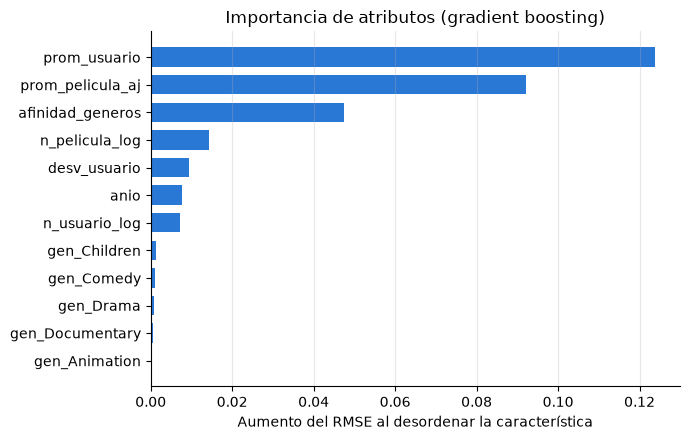

In [14]:
# ¿Qué atributos usa el gradient boosting? Importancia por permutación sobre las filas de test
X_te = atributos(estadisticas(train), test["u"].to_numpy(), test["i"].to_numpy())   # características de los pares de test
imp = permutation_importance(modelos_atr["Gradient boosting (atributos)"], X_te, test["rating"].to_numpy(),
                             scoring="neg_root_mean_squared_error", n_repeats=5, random_state=SEMILLA)
imp = pd.Series(imp.importances_mean, index=NOMBRES_ATR).sort_values().tail(12)     # las 12 más importantes
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(imp.index, imp.values, color=COLORES[0], height=0.7)                        # barras horizontales
ax.set_xlabel("Aumento del RMSE al desordenar la característica")
ax.set_title("Importancia de atributos (gradient boosting)"); ax.grid(axis="y", alpha=0)
plt.tight_layout(); fig.savefig("figuras/fig_importancia.png", dpi=200, bbox_inches="tight"); plt.show()

**Qué es la importancia por permutación.** Se toma una columna de la tabla de características (por ejemplo, el año) y se **revuelven sus valores al azar** entre las filas, dejando todo lo demás igual. Si el modelo dependía de esa columna, ahora se equivocará más. El aumento del error (RMSE) es su importancia. Se repite 5 veces y se promedia.

**Cómo se lee.** Cada barra es una característica; cuanto más larga, más depende el modelo de ella. Una barra de 0.05 quiere decir que, sin esa información, el RMSE sube 0.05 estrellas. Una barra cercana a 0 (o negativa) significa que el modelo prácticamente no la usa.

**Qué muestra.** Las barras más largas son *prom_pelicula_aj* (qué tan bien califican todos a la película), *prom_usuario* (qué tan generoso es el usuario) y *afinidad_generos*; los indicadores de género sueltos (*gen_…*) y el año son pequeños. Esto responde "¿sirven los atributos de la película para predecir la nota?": por sí solos aportan poco frente a lo que dicen las calificaciones, pero los gustos del usuario por género sí ayudan.

**Advertencia.** La importancia es descriptiva: dice qué usa *este* modelo, no qué causa que a alguien le guste una película. Tampoco se usó para elegir nada, así que calcularla sobre test no contamina la evaluación.

## 9. Evaluación: comparación final

**Qué se hace.** Se reúnen los resultados en `test` de todos los modelos, se comparan contra el baseline de cada tarea usuario por usuario (con intervalo de confianza del 95 %), se estudia la relación entre las dos tareas y se desglosan los resultados por tipo de usuario y para películas nuevas.

**Por qué.** Una diferencia en la tercera cifra decimal puede ser azar; el intervalo pareado dice si es real. Los desgloses responden a la pregunta P3 (poco historial y arranque en frío).

### 9.1 Tabla completa

In [15]:
print("TAREA 1: predecir la nota (menor es mejor)")
display(tabla({n: r for n, r in resultados.items() if "RMSE" in r}, COL_NOTA).sort_values("RMSE").round(3))   # ordenada de mejor a peor
print("\nTAREA 2: lista de 10 (mayor es mejor, salvo popularidad media, que es descriptiva)")
display(tabla({n: r for n, r in resultados.items() if "NDCG@10" in r}, COL_LISTA).sort_values("NDCG@10", ascending=False).round(3))

TAREA 1: predecir la nota (menor es mejor)


,RMSE,MAE
Gradient boosting (atributos),0.919,0.697
Regresión lineal (atributos),0.937,0.713
"SVD (f=20, reg=0.02, ajustado a nota)",0.943,0.718
Sesgos usuario + película,0.944,0.724
"SVD (f=100, reg=0.02, ajustado a lista)",0.946,0.721
"k-NN de usuarios (k=320, ajustado a nota)",0.955,0.725
"k-NN de películas (k=320, ajustado a nota)",0.958,0.720
"k-NN de usuarios (k=10, ajustado a lista)",1.000,0.760
"k-NN de películas (k=10, ajustado a lista)",1.018,0.764
Promedio del usuario,1.022,0.785



TAREA 2: lista de 10 (mayor es mejor, salvo popularidad media, que es descriptiva)


,NDCG@10,Hit@10 (le gustó),Hit@10 (cualquiera),Precision@10,Cobertura,Popularidad media
k-NN de películas para listas (k=20),0.068,0.314,0.356,0.048,0.067,147.609
Más calificadas,0.054,0.247,0.275,0.037,0.013,220.029
Mejor promedio ajustado,0.040,0.189,0.202,0.027,0.007,150.393
Gradient boosting (atributos),0.034,0.174,0.190,0.022,0.065,111.966
Sesgos usuario + película,0.031,0.165,0.180,0.020,0.008,136.426
Regresión lineal (atributos),0.029,0.151,0.166,0.021,0.025,105.175
"SVD (f=100, reg=0.02, ajustado a lista)",0.021,0.118,0.143,0.015,0.040,88.805
"k-NN de películas (k=10, ajustado a lista)",0.015,0.080,0.090,0.009,0.246,42.319
"k-NN de usuarios (k=10, ajustado a lista)",0.002,0.012,0.016,0.001,0.119,20.493
Aleatorio,0.001,0.007,0.008,0.001,0.476,8.886


Son las mismas cifras de las secciones anteriores, juntas y **ordenadas de mejor a peor**: por RMSE (de menor a mayor) en la tarea 1 y por NDCG@10 (de mayor a menor) en la tarea 2. Las dos preguntas que responden:
1. **¿Quién queda arriba en cada tarea?** En la tarea 1, el gradient boosting; en la tarea 2, el k-NN para listas, seguido de *Más calificadas*: recomendar lo popular es muy difícil de superar en estos datos.
2. **¿Es el mismo modelo en las dos tablas?** No: el gradient boosting queda en cuarto lugar en la tarea 2 y el k-NN para listas no predice notas. Predecir la nota y recomendar son problemas distintos (lo explora 9.3).

El orden solo dice quién tuvo la cifra mayor en esta prueba, no si la diferencia es real. Eso lo dice la siguiente sección.

### 9.2 ¿La diferencia con el baseline es real? (comparación pareada)

Todos los modelos se evalúan con los **mismos usuarios**, así que se compara usuario por usuario: para cada uno se calcula la diferencia de la métrica entre el modelo y el baseline, y luego el promedio de esas diferencias con su intervalo de confianza del 95 %. **Si el intervalo no incluye el 0, la diferencia es real**; si lo incluye, no se puede afirmar que un modelo sea mejor.

- Tarea 1: diferencia en el error cuadrático medio por usuario (negativo = el modelo se equivoca menos).
- Tarea 2: diferencia en NDCG@10 por usuario (positivo = el modelo recomienda mejor).

In [16]:
# Diferencia media pareada y su intervalo de confianza del 95 %
def comparar(a, b):
    d = a - b                                            # diferencia usuario por usuario
    d = d[~np.isnan(d)]                                  # se quitan usuarios sin valor
    ic = 1.96 * d.std(ddof=1) / np.sqrt(len(d))          # margen del intervalo de confianza del 95 %
    return d.mean(), d.mean() - ic, d.mean() + ic        # diferencia media, límite inferior, límite superior

# Cada modelo contra el baseline de su tarea
REF_NOTA, REF_LISTA = "Sesgos usuario + película", "Más calificadas"
filas = []
for n, r in resultados.items():
    if "_mse_u" in r and n != REF_NOTA:                  # modelos que hacen la tarea 1
        m, lo, hi = comparar(r["_mse_u"], resultados[REF_NOTA]["_mse_u"])
        filas.append({"Tarea": "1. Nota (Δ error cuadrático)", "Modelo": n, "Diferencia": m, "IC inf": lo, "IC sup": hi,
                      "¿Mejor que el baseline?": "sí" if hi < 0 else ("no, peor" if lo > 0 else "no se distingue")})
    if "_ndcg_u" in r and n != REF_LISTA:                # modelos que hacen la tarea 2
        m, lo, hi = comparar(r["_ndcg_u"], resultados[REF_LISTA]["_ndcg_u"])
        filas.append({"Tarea": "2. Lista (Δ NDCG@10)", "Modelo": n, "Diferencia": m, "IC inf": lo, "IC sup": hi,
                      "¿Mejor que el baseline?": "sí" if lo > 0 else ("no, peor" if hi < 0 else "no se distingue")})
pareada = pd.DataFrame(filas)
print(f"Referencia tarea 1: {REF_NOTA} | referencia tarea 2: {REF_LISTA}")
pareada.round(4)

Referencia tarea 1: Sesgos usuario + película | referencia tarea 2: Más calificadas


,Tarea,Modelo,Diferencia,IC inf,IC sup,¿Mejor que el baseline?
0,2. Lista (Δ NDCG@10),Aleatorio,-0.0534,-0.0632,-0.0436,"no, peor"
1,1. Nota (Δ error cuadrático),Promedio global,0.3220,0.2759,0.3682,"no, peor"
2,1. Nota (Δ error cuadrático),Promedio del usuario,0.1532,0.1206,0.1858,"no, peor"
3,1. Nota (Δ error cuadrático),Promedio de la película,0.1920,0.1453,0.2388,"no, peor"
4,2. Lista (Δ NDCG@10),Promedio de la película,-0.0544,-0.0641,-0.0447,"no, peor"
5,2. Lista (Δ NDCG@10),Sesgos usuario + película,-0.0232,-0.0319,-0.0144,"no, peor"
6,2. Lista (Δ NDCG@10),Mejor promedio ajustado,-0.0142,-0.0228,-0.0057,"no, peor"
7,1. Nota (Δ error cuadrático),"k-NN de películas (k=320, ajustado a nota)",0.0267,-0.0127,0.0661,no se distingue
8,1. Nota (Δ error cuadrático),"k-NN de películas (k=10, ajustado a lista)",0.1467,0.1130,0.1804,"no, peor"
9,2. Lista (Δ NDCG@10),"k-NN de películas (k=10, ajustado a lista)",-0.0397,-0.0502,-0.0292,"no, peor"


**El problema que resuelve.** Con 610 usuarios, dos modelos pueden diferir en la tercera cifra decimal solo por azar: unos usuarios favorecen a uno y otros al otro. Hace falta saber si la diferencia es mayor que lo que el azar produciría.

**Qué es la comparación pareada.** Como los dos modelos se probaron con los mismos usuarios, para cada usuario se resta "error del modelo − error del baseline". Así se compara a cada usuario consigo mismo, y las diferencias entre usuarios fáciles y difíciles dejan de estorbar. Luego se promedian esas 610 restas.

**Qué es el intervalo de confianza del 95 %.** Es un rango alrededor de la diferencia promedio que indica dónde estaría la diferencia "verdadera" si se repitiera el experimento con otros usuarios parecidos. Se calcula como promedio ± 1.96 × (desviación de las restas ÷ raíz del número de usuarios). Más usuarios, o restas más parecidas entre sí, dan un intervalo más angosto.

**Columnas de la tabla:**
- *Diferencia*: el promedio de las restas. En la tarea 1, **negativo es bueno** (el modelo se equivoca menos). En la tarea 2, **positivo es bueno** (el modelo ordena mejor).
- *IC inf* e *IC sup*: los dos extremos del intervalo.
- *¿Mejor que el baseline?*:
  - **"sí"** si todo el intervalo está del lado bueno del 0. Ejemplo en la tarea 1: el gradient boosting, de −0.076 a −0.016.
  - **"no, peor"** si todo el intervalo está del lado malo.
  - **"no se distingue"** si el intervalo cruza el 0, como el SVD ajustado a nota, de −0.012 a +0.009. Con estos datos no se puede afirmar que uno sea mejor.

**Cuidado.** Una diferencia puede ser real pero pequeña. Por eso se reportan las dos cosas: si la diferencia existe (el intervalo) y qué tan grande es (la diferencia en RMSE o NDCG).

### Variabilidad: intervalos de confianza de la comparación pareada

**Qué se hace.** Se grafica cada diferencia media con su intervalo de confianza del 95 %, una fila por modelo. Se omiten los baselines triviales (aleatorio y promedios simples) y, en la tarea 1, las versiones "ajustadas a lista", porque sus diferencias son mucho mayores y aplastarían la escala.

**Por qué.** La gráfica muestra de un vistazo cuáles diferencias son reales (el intervalo no toca la línea del 0) y cuánta incertidumbre tiene cada una. Es la figura principal del artículo (`figuras/fig_ic.png`).

En la gráfica, verde = mejor que el baseline; rojo = peor; gris = no se distingue. En la tarea 1, a la izquierda del 0 es mejor (menos error); en la tarea 2, a la derecha del 0 es mejor (más NDCG).

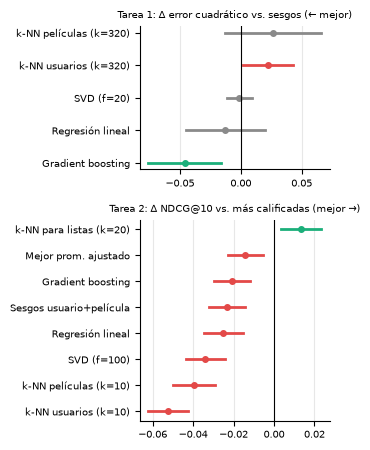

In [17]:
# Gráfica de intervalos de confianza (variabilidad de las diferencias pareadas)
def abreviar(n):
    """Nombre corto de un modelo para las figuras del artículo."""
    for a, b in [("k-NN de películas para listas", "k-NN para listas"), ("Sesgos usuario + película", "Sesgos usuario+película"),
                 (" (atributos)", ""), (", ajustado a nota", ""), (", ajustado a lista", ""), (", reg=0.02", ""),
                 ("k-NN de películas", "k-NN películas"), ("k-NN de usuarios", "k-NN usuarios"),
                 ("Mejor promedio ajustado", "Mejor prom. ajustado"), ("Regresión lineal", "Regresión lineal")]:
        n = n.replace(a, b)
    return n

TRIVIALES = {"Aleatorio", "Promedio global", "Promedio del usuario", "Promedio de la película"}
COLOR_VEREDICTO = {"sí": COLORES[2], "no, peor": COLORES[7], "no se distingue": "#8a8a8a"}
fig, ax = plt.subplots(2, 1, figsize=(3.5, 4.6), gridspec_kw={"height_ratios": [5, 7]})   # ancho de una columna IEEE
for a, tarea, encabezado in [(ax[0], "1. Nota (Δ error cuadrático)", "Tarea 1: Δ error cuadrático vs. sesgos (← mejor)"),
                         (ax[1], "2. Lista (Δ NDCG@10)", "Tarea 2: Δ NDCG@10 vs. más calificadas (mejor →)")]:
    d = pareada[(pareada["Tarea"] == tarea) & ~pareada["Modelo"].isin(TRIVIALES)]
    if tarea.startswith("1"):
        d = d[~d["Modelo"].str.contains("ajustado a lista")]        # en la tarea 1 solo las versiones ajustadas a nota
    d = d.sort_values("Diferencia")
    for y, (_, f) in enumerate(d.iterrows()):                         # una fila por modelo
        c = COLOR_VEREDICTO[f["¿Mejor que el baseline?"]]
        a.plot([f["IC inf"], f["IC sup"]], [y, y], color=c, lw=2)     # intervalo de confianza del 95 %
        a.plot(f["Diferencia"], y, "o", color=c, ms=4)                # diferencia media
    a.axvline(0, color="black", lw=0.8)                               # línea de "sin diferencia"
    a.set_yticks(range(len(d)), [abreviar(n) for n in d["Modelo"]], fontsize=7)
    a.tick_params(axis="x", labelsize=7); a.set_title(encabezado, fontsize=7.5); a.grid(axis="y", alpha=0)
plt.tight_layout(); fig.savefig("figuras/fig_ic.png", dpi=300, bbox_inches="tight"); plt.show()

### 9.3 ¿El que mejor predice la nota es el que mejor recomienda?

Cada punto es un modelo que hace las dos tareas. Si los mejores en nota (izquierda) fueran también los mejores en lista (arriba), los puntos formarían una diagonal descendente.

Clave de los puntos:
   1. Aleatorio
   2. Promedio de la película
   3. Sesgos usuario + película
   4. Más calificadas
   5. Mejor promedio ajustado
   6. k-NN de películas (k=10, ajustado a lista)
   7. k-NN de usuarios (k=10, ajustado a lista)
   8. k-NN de películas para listas (k=20)
   9. SVD (f=100, reg=0.02, ajustado a lista)
  10. Regresión lineal (atributos)
  11. Gradient boosting (atributos)


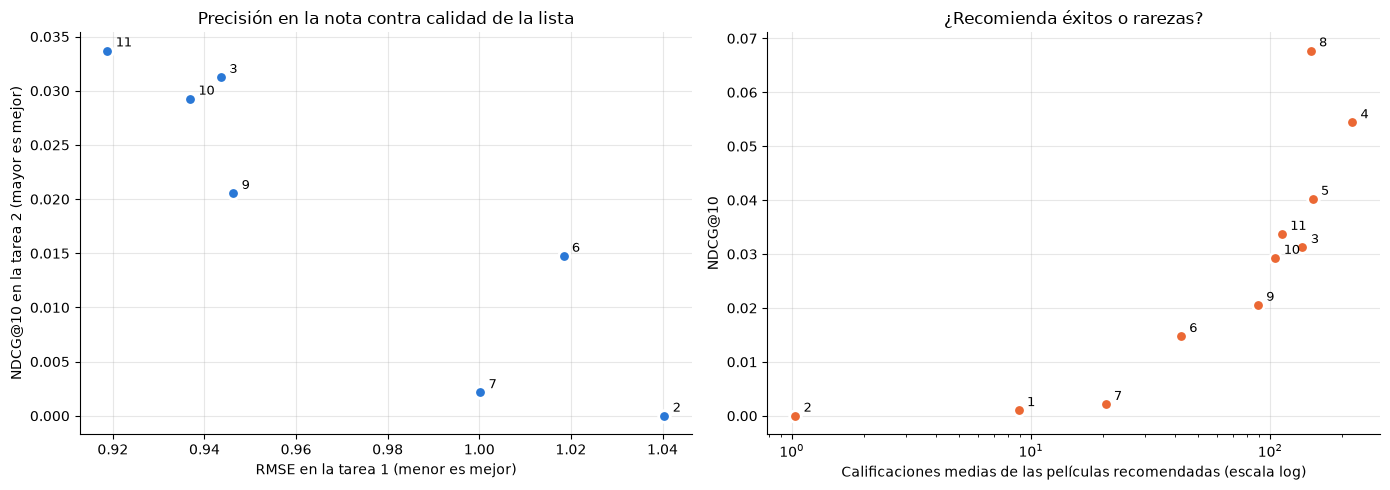

In [18]:
# Dos diagramas de dispersión con un número por modelo
ambos = tabla({n: r for n, r in resultados.items() if "RMSE" in r and "NDCG@10" in r})   # modelos que hacen las dos tareas
lista = tabla({n: r for n, r in resultados.items() if "NDCG@10" in r})                   # modelos que hacen la tarea 2
numero = {n: j + 1 for j, n in enumerate(lista.index)}          # cada modelo se marca con un número
print("Clave de los puntos:\n" + "\n".join(f"  {j:>2}. {n}" for n, j in numero.items()))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for a, d, x, color in [(ax[0], ambos, "RMSE", COLORES[0]), (ax[1], lista, "Popularidad media", COLORES[1])]:
    a.scatter(d[x], d["NDCG@10"], s=70, color=color, edgecolor="white", linewidth=2, zorder=3)   # un punto por modelo
    for n, f in d.iterrows():
        a.annotate(str(numero[n]), (f[x], f["NDCG@10"]), fontsize=9, xytext=(6, 3), textcoords="offset points")   # su número
ax[0].set_xlabel("RMSE en la tarea 1 (menor es mejor)"); ax[0].set_ylabel("NDCG@10 en la tarea 2 (mayor es mejor)")
ax[0].set_title("Precisión en la nota contra calidad de la lista")
ax[1].set_xscale("log"); ax[1].set_xlabel("Calificaciones medias de las películas recomendadas (escala log)")
ax[1].set_ylabel("NDCG@10"); ax[1].set_title("¿Recomienda éxitos o rarezas?")
plt.tight_layout(); fig.savefig("figuras/fig_rmse_ndcg.png", dpi=200, bbox_inches="tight"); plt.show()

Son **diagramas de dispersión**: cada punto es un modelo, colocado según dos medidas (una en cada eje). El número junto al punto se busca en la *Clave de los puntos* impresa arriba de la gráfica.

**Izquierda: precisión en la nota contra calidad de la lista.** Eje horizontal: RMSE de la tarea 1 (**más a la izquierda es mejor**). Eje vertical: NDCG@10 de la tarea 2 (**más arriba es mejor**).
- Si predecir bien la nota llevara a recomendar bien, los puntos de la izquierda estarían arriba y los de la derecha abajo, formando una diagonal que baja hacia la derecha.
- Lo que se ve es otra cosa: modelos con RMSE parecido (apiñados a la izquierda) y NDCG muy distinto, y el de mejor RMSE (gradient boosting) con NDCG por debajo de la popularidad. Eso significa que **acertar la nota no garantiza una buena lista**. La razón: el RMSE solo se mide en películas que el usuario sí vio, mientras que la lista se elige entre miles de películas que no vio, y ahí el modelo puede sobrevalorar rarezas (Cremonesi, Koren y Turrin, 2010).

**Derecha: ¿recomienda éxitos o rarezas?** Eje horizontal: cuántas calificaciones tienen, en promedio, las películas que recomienda el modelo, en escala logarítmica (1, 10, 100, 1000). **A la izquierda recomienda rarezas; a la derecha, éxitos.** Eje vertical: NDCG@10.
- Los puntos suben de izquierda a derecha: los modelos que recomiendan películas conocidas aciertan más.
- Esto **no significa que recomendar lo popular sea "lo correcto"**. Las películas populares son las que más gente termina calificando, así que es más fácil "acertar" con ellas en la prueba. Es un **sesgo de popularidad** de la evaluación misma, y es una limitación del estudio.
- Un modelo útil sería uno que esté arriba (acierta) sin estar en el extremo derecho (no recomienda solo lo obvio).

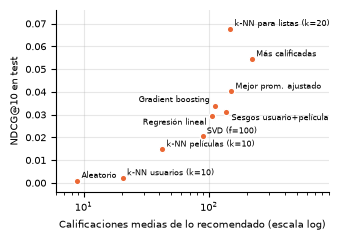

In [19]:
# Versión compacta de "NDCG@10 contra popularidad" para el artículo (una columna IEEE)
lista_c = tabla({n: r for n, r in resultados.items() if "NDCG@10" in r}).query("`NDCG@10` > 0")   # sin el NDCG nulo (escala log)
fig, ax = plt.subplots(figsize=(3.5, 2.5))
ax.scatter(lista_c["Popularidad media"], lista_c["NDCG@10"], s=22, color=COLORES[1], edgecolor="white", zorder=3)
POS = {"Gradient boosting": (-4, 3, "right"), "Regresión lineal": (-4, -6, "right"),   # etiquetas que se enciman:
       "Sesgos usuario+película": (4, -6, "left")}                                     # se mueven a otro lado
for n, f in lista_c.iterrows():                                     # etiqueta corta junto a cada punto
    dx, dy, ha = POS.get(abreviar(n), (3, 2, "left"))
    ax.annotate(abreviar(n), (f["Popularidad media"], f["NDCG@10"]), fontsize=5.5, xytext=(dx, dy),
                textcoords="offset points", ha=ha)
ax.set_xscale("log"); ax.set_xlim(6, 900)                           # margen para que quepan las etiquetas
ax.set_ylim(-0.004, 0.076); ax.set_xlabel("Calificaciones medias de lo recomendado (escala log)", fontsize=7)
ax.set_ylabel("NDCG@10 en test", fontsize=7); ax.tick_params(labelsize=7)
plt.tight_layout(); fig.savefig("figuras/fig_popularidad.png", dpi=300, bbox_inches="tight"); plt.show()

### 9.4 Resultados por tipo de usuario

Los usuarios se dividen en tres grupos de igual tamaño según cuántas calificaciones tienen en `train`. Así se ve si algún método funciona mejor con usuarios poco activos (lo más parecido a un "usuario nuevo" que hay en estos datos).

In [20]:
# Grupos de usuarios por actividad y métricas por grupo
grupo = pd.qcut(n_train_u, 3, labels=["pocas", "medias", "muchas"])   # tres grupos con el mismo número de usuarios
cortes = n_train_u.groupby(grupo, observed=True).agg(["min", "max"]) # dónde quedaron los cortes
print("Calificaciones en train por grupo:\n", cortes, "\n")
g_test = grupo.to_numpy()[test["u"].to_numpy()]                       # el grupo de cada fila de test
seleccion = [n for n in resultados if n in (REF_NOTA, REF_LISTA) or "Aleatorio" not in n and "Promedio" not in n]   # sin baselines débiles

filas = []
for n in seleccion:
    r = resultados[n]
    fila = {"Modelo": n}
    for g in ["pocas", "medias", "muchas"]:
        if "_err" in r:
            fila[f"RMSE {g}"] = np.sqrt(np.mean(r["_err"][g_test == g] ** 2))       # RMSE solo con usuarios del grupo
        if "_ndcg_u" in r:
            fila[f"NDCG {g}"] = np.nanmean(r["_ndcg_u"][grupo.to_numpy() == g])     # NDCG solo con usuarios del grupo
    filas.append(fila)
por_grupo = pd.DataFrame(filas).set_index("Modelo")
por_grupo.round(3)

Calificaciones en train por grupo:
         min   max
pocas    10    35
medias   36   117
muchas  118  2688 



,RMSE pocas,NDCG pocas,RMSE medias,NDCG medias,RMSE muchas,NDCG muchas
Modelo,,,,,,
Sesgos usuario + película,1.007,0.041,0.909,0.032,0.908,0.020
Más calificadas,NaN,0.086,NaN,0.041,NaN,0.033
Mejor promedio ajustado,NaN,0.058,NaN,0.042,NaN,0.018
"k-NN de películas (k=320, ajustado a nota)",1.073,NaN,0.902,NaN,0.882,NaN
"k-NN de películas (k=10, ajustado a lista)",1.069,0.027,1.027,0.010,0.955,0.006
"k-NN de usuarios (k=320, ajustado a nota)",1.021,NaN,0.917,NaN,0.922,NaN
"k-NN de usuarios (k=10, ajustado a lista)",1.062,0.003,0.979,0.002,0.955,0.002
k-NN de películas para listas (k=20),NaN,0.104,NaN,0.057,NaN,0.038
"SVD (f=20, reg=0.02, ajustado a nota)",1.010,NaN,0.910,NaN,0.902,NaN


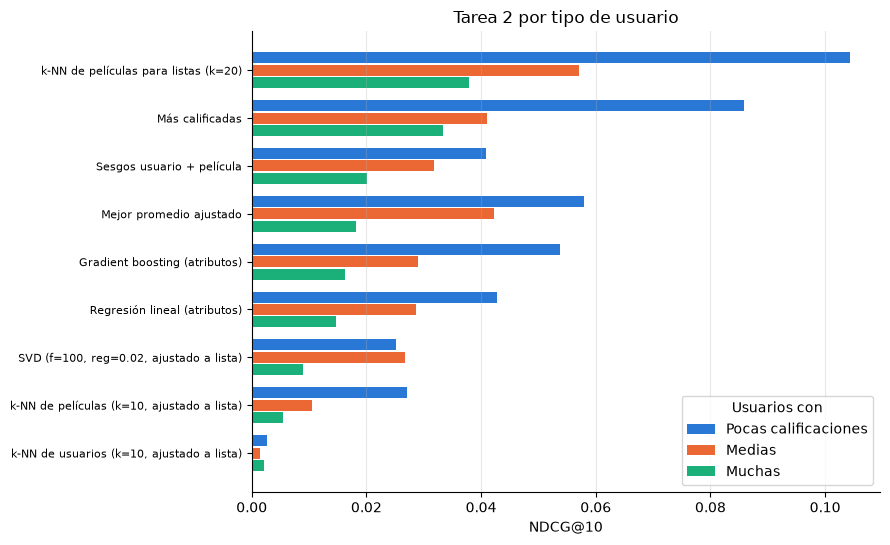

In [21]:
# Barras agrupadas: un grupo de tres barras por modelo
cols_nd = [c for c in por_grupo.columns if c.startswith("NDCG")]
datos = por_grupo[cols_nd].dropna().sort_values("NDCG muchas")       # solo modelos de la tarea 2
fig, ax = plt.subplots(figsize=(9, 0.45 * len(datos) + 1.5))         # la altura crece con el número de modelos
y = np.arange(len(datos)); h = 0.26                                   # posición de cada modelo y grosor de barra
for j, (c, nom) in enumerate(zip(cols_nd, ["Pocas calificaciones", "Medias", "Muchas"])):
    ax.barh(y + (1 - j) * h, datos[c], height=h - 0.03, color=COLORES[j], label=nom)   # desplaza cada grupo un poco
ax.set_yticks(y, datos.index, fontsize=8); ax.set_xlabel("NDCG@10"); ax.grid(axis="y", alpha=0)
ax.set_title("Tarea 2 por tipo de usuario"); ax.legend(title="Usuarios con", loc="lower right")
plt.tight_layout(); fig.savefig("figuras/fig_grupos.png", dpi=200, bbox_inches="tight"); plt.show()

**Cómo se hicieron los grupos.** `qcut` divide a los usuarios en tres grupos con el mismo número de personas, según cuántas calificaciones tienen en `train`: *pocas* (de 10 a 35), *medias* (de 36 a 117) y *muchas* (de 118 a 2,688).

**La tabla.** Cada modelo tiene su RMSE y su NDCG calculados por separado para cada grupo. A lo largo de una fila se ve cómo cambia un mismo modelo según el tipo de usuario; a lo largo de una columna, qué modelo gana dentro de un grupo.

**La gráfica.** Cada modelo tiene tres barras, una por grupo, con los colores de la leyenda. Barra más larga = mejor NDCG en ese grupo.

**Qué muestran:**
- **En RMSE**, los usuarios con más calificaciones tienen menor error: con más historial se les conoce mejor (sesgos: 1.007 en *pocas* y 0.908 en *muchas*). Con *pocas* calificaciones ningún modelo mejora de forma apreciable a los sesgos; los modelos personalizados ganan con historial medio o grande. Necesitan historial para funcionar.
- **En NDCG** pasa lo contrario de lo intuitivo: los usuarios con *pocas* calificaciones tienen el NDCG más alto (0.086 con *Más calificadas*). Suelen ser usuarios que vieron sobre todo éxitos, y sus películas escondidas también lo son, así que la lista de populares los acierta. Los usuarios muy activos ya vieron los éxitos, y lo que les queda por ver es más raro y difícil de adivinar.
- **El k-NN para listas supera a *Más calificadas* en los tres grupos** (0.104, 0.057 y 0.038 contra 0.086, 0.041 y 0.033).
- Cada grupo tiene solo ~200 usuarios, así que las diferencias pequeñas entre grupos pueden ser azar.

### 9.5 Películas nuevas: calificaciones de test sobre películas que no estaban en `train`

Para esas películas el sistema no tiene ninguna nota. Los métodos de historial (sesgos, k-NN, SVD) solo pueden usar el promedio del usuario; el modelo por atributos todavía conoce su género y año. Aquí se ve si eso ayuda.

En la tarea 2 estas películas no pueden recomendarse (no están en el catálogo conocido), así que el análisis es solo de la tarea 1.

In [22]:
# Error separado para películas conocidas y nuevas
nueva = ~test["i"].isin(train["i"]).to_numpy()                       # True = película sin ninguna nota en train
print(f"Calificaciones de test sobre películas nuevas: {nueva.sum()} de {len(nueva)} ({nueva.mean():.1%})\n")
filas = []
for n, r in resultados.items():
    if "_err" in r:
        filas.append({"Modelo": n, "RMSE películas conocidas": np.sqrt(np.mean(r["_err"][~nueva] ** 2)),
                      "RMSE películas nuevas": np.sqrt(np.mean(r["_err"][nueva] ** 2))})
pd.DataFrame(filas).set_index("Modelo").sort_values("RMSE películas nuevas").round(3)

Calificaciones de test sobre películas nuevas: 204 de 6100 (3.3%)



,RMSE películas conocidas,RMSE películas nuevas
Modelo,,
Gradient boosting (atributos),0.914,1.057
"SVD (f=100, reg=0.02, ajustado a lista)",0.942,1.069
"SVD (f=20, reg=0.02, ajustado a nota)",0.938,1.071
"k-NN de usuarios (k=10, ajustado a lista)",0.998,1.074
"k-NN de películas (k=10, ajustado a lista)",1.016,1.074
"k-NN de usuarios (k=320, ajustado a nota)",0.951,1.074
"k-NN de películas (k=320, ajustado a nota)",0.953,1.074
Sesgos usuario + película,0.939,1.074
Regresión lineal (atributos),0.932,1.076


La primera línea indica cuántas calificaciones de test son sobre películas "nuevas" (que nadie había calificado en `train`): 204 de 6,100 (3.3 %). Con tan pocos casos, el RMSE de esa columna es menos estable y se interpreta como indicio, no como prueba.

La tabla separa el error de cada modelo en dos columnas: películas **conocidas** y **nuevas**, ordenada por la columna de nuevas.
- El error en películas nuevas es **mayor** para todos: sin información de la película, el modelo solo sabe cómo suele calificar el usuario.
- Los modelos de historial (sesgos, k-NN) tienen exactamente el mismo error en películas nuevas (1.074), porque para ellas todos se reducen a "promedio global + sesgo del usuario".
- El **gradient boosting**, que conoce el género y el año, queda primero en la columna de nuevas, pero solo baja el RMSE de 1.074 a 1.057. Conocer el género y el año ayuda un poco cuando no hay calificaciones; son atributos demasiado pobres para compensar la falta de historial.

## 10. Agrupamiento: K-means sobre los factores del SVD

**K-means** es un método de **aprendizaje no supervisado**: no hay una respuesta correcta que aprender, solo se buscan grupos de elementos parecidos. Se elige un número de grupos *K*; el algoritmo coloca *K* "centros" y asigna cada película al centro más cercano, mueve cada centro al promedio de sus películas y repite hasta que nada cambia.

Aquí cada película queda descrita por sus factores del SVD (sus "números ocultos" de gusto). Las películas que gustan a la misma clase de usuarios deberían caer en el mismo grupo. Después se revisa si los grupos coinciden con géneros o épocas. Solo se usan películas con al menos 20 calificaciones en `train`, porque las demás tienen factores poco confiables. Es un análisis exploratorio: no responde a ninguna de las dos tareas.

In [23]:
from sklearn.cluster import KMeans                       # algoritmo K-means
from sklearn.metrics import silhouette_score             # medida de qué tan separados quedan los grupos

# Elegir el número de grupos con la silueta y agrupar
n_i_train = np.bincount(train["i"], minlength=NI)        # calificaciones de cada película en train
sel = np.where(n_i_train >= 20)[0]                       # películas con al menos 20 notas
F = svd_final["Qi"][sel]                                 # sus factores del SVD
F = F / np.maximum(np.linalg.norm(F, axis=1, keepdims=True), 1e-12)     # se compara la dirección de los gustos, no el tamaño
print("Películas agrupadas:", len(sel))

sil = {}
for k_ in range(3, 11):                                  # se prueban de 3 a 10 grupos
    et = KMeans(n_clusters=k_, n_init=10, random_state=SEMILLA).fit_predict(F)
    sil[k_] = silhouette_score(F, et, random_state=SEMILLA)
print("Silueta por número de grupos:", {k_: round(v, 3) for k_, v in sil.items()})
K_GRUPOS = max(sil, key=sil.get)                         # el K con mayor silueta
print("Se usa K =", K_GRUPOS, "(la silueta más alta). Siluetas menores a 0.1 indican grupos débiles.")
etiquetas = KMeans(n_clusters=K_GRUPOS, n_init=10, random_state=SEMILLA).fit_predict(F)   # grupo de cada película

Películas agrupadas: 1223


Silueta por número de grupos: {3: 0.046, 4: 0.044, 5: 0.043, 6: 0.042, 7: 0.04, 8: 0.04, 9: 0.041, 10: 0.042}
Se usa K = 3 (la silueta más alta). Siluetas menores a 0.1 indican grupos débiles.


In [24]:
# Descripción de cada grupo
gen_sel = pd.DataFrame(GEN[sel], columns=generos.columns)                    # géneros de las películas agrupadas
base_gen = gen_sel.mean()                                                    # proporción de cada género en todas ellas
for g in range(K_GRUPOS):
    m = etiquetas == g                                                       # películas del grupo g
    lift = (gen_sel[m].mean() / base_gen).replace([np.inf], np.nan).dropna() # proporción en el grupo ÷ proporción general
    gen_top = ", ".join(f"{c} ×{v:.1f}" for c, v in lift.sort_values(ascending=False).head(3).items())
    pel = sel[m][np.argsort(-n_i_train[sel[m]])][:5]                         # las 5 más calificadas del grupo
    print(f"Grupo {g}: {m.sum()} películas | año mediano {np.median(ANIO[sel[m]]):.0f} | "
          f"nota media {media_pelicula(train)[sel[m]].mean():.2f}")
    print(f"   géneros más sobrerrepresentados: {gen_top}")
    print(f"   más vistas: {'; '.join(titulo[peliculas_ids[pel]].tolist())}\n")

Grupo 0: 408 películas | año mediano 1996 | nota media 3.57
   géneros más sobrerrepresentados: Children ×1.4, Musical ×1.3, Fantasy ×1.3
   más vistas: Forrest Gump (1994); Toy Story (1995); Schindler's List (1993); Apollo 13 (1995); Fugitive, The (1993)

Grupo 1: 414 películas | año mediano 1997 | nota media 3.69
   géneros más sobrerrepresentados: Documentary ×1.8, Film-Noir ×1.6, Horror ×1.4
   más vistas: Pulp Fiction (1994); Shawshank Redemption, The (1994); Matrix, The (1999); Silence of the Lambs, The (1991); Star Wars: Episode IV - A New Hope (1977)

Grupo 2: 401 películas | año mediano 1998 | nota media 3.30
   géneros más sobrerrepresentados: Thriller ×1.3, Action ×1.2, Sci-Fi ×1.2
   más vistas: Jurassic Park (1993); Independence Day (a.k.a. ID4) (1996); Speed (1994); Shrek (2001); Mission: Impossible (1996)



**La silueta.** Es un número entre −1 y 1 que mide qué tan bien separados quedaron los grupos. Para cada película compara qué tan cerca está de las de su grupo contra qué tan cerca está del grupo vecino. Cerca de 1, grupos compactos y bien separados; cerca de 0, grupos que se tocan y fronteras arbitrarias; negativa, películas probablemente mal asignadas. Se usa el *K* con la silueta más alta.

**Resultado.** La silueta es baja (0.040 a 0.046 para K de 3 a 10), algo habitual en gustos de películas. No es un error: los gustos no forman islas separadas, sino un continuo. Los grupos existen, pero sus fronteras son difusas.

**La descripción de cada grupo:**
- *Año mediano* y *nota media*: si un grupo tiene año mediano 1975 y otro 2010, el SVD distingue épocas. Si un grupo tiene nota media claramente más alta, distingue "clásicos aclamados" de "películas del montón".
- *Géneros más sobrerrepresentados*: "Horror ×2.5" significa que la proporción de películas de terror en ese grupo es 2.5 veces la proporción en el conjunto completo. Valores cercanos a ×1 significan que ese género no caracteriza al grupo.
- *Más vistas*: los 5 títulos más conocidos del grupo, que ayudan a ponerle un nombre.

**Interpretación.** Los tres grupos tienen casi el mismo año mediano (1996–1998), así que no separan épocas. Se distinguen más por tipo de gusto y nota media: clásicos familiares y populares (3.57), cine aclamado con documental y cine negro (3.69), y acción y ciencia ficción taquillera (3.30). Los géneros sobrerrepresentados son moderados (×1.2 a ×1.8): el SVD capta gustos que no coinciden del todo con las etiquetas de género.

## 11. Análisis de errores: ejemplo con un usuario concreto

**Qué se hace.** Para un usuario se muestran sus últimas calificaciones conocidas, las 10 que se le escondieron y las listas de dos modelos, marcando los aciertos.

**Por qué.** Las métricas promedian; un caso concreto muestra *cómo* se equivoca cada modelo. Aquí se ve que la popularidad acierta con éxitos que casi todos ven, mientras que las películas que más le gustaron al usuario (nota 5) son poco conocidas y ningún modelo las propone.

La variable `USUARIO` define el `userId` mostrado; cualquier otro valor produce el mismo análisis para ese usuario.

In [25]:
# Historial, películas escondidas y listas de dos modelos para un usuario
USUARIO = usuarios_ids[0]                                                    # el userId que se quiere ver
u = fila_de[USUARIO]                                                         # su número de fila
nombres_baselines = [b[0] for b in baselines]
mejor_lista = tabla({n: r for n, r in resultados.items()
                     if "NDCG@10" in r and n not in nombres_baselines}).sort_values("NDCG@10").index[-1]   # mejor modelo personalizado

print(f"Usuario {USUARIO}: {n_train_u[u]} calificaciones en train\n")
print("Sus 5 últimas en train:")
for _, f in train[train.u == u].tail(5).iterrows():                          # tail(5) = las 5 últimas filas
    print(f"   {f['rating']:.1f}  {titulo[f['movieId']]}")
esc = test[test.u == u]
print("\nEscondidas (test):")
for _, f in esc.iterrows():
    print(f"   {f['rating']:.1f}  {titulo[f['movieId']]}")
gusta = set(esc.loc[esc.gusto == 1, "i"]); vistas = set(esc["i"])
for n in [REF_LISTA, mejor_lista]:
    print(f"\nLista de {n}" + (" (el mejor modelo personalizado en NDCG@10):" if n == mejor_lista else ":"))
    for j in resultados[n]["_tops"][u]:
        marca = "  ← le gustó" if j in gusta else ("  ← la vio" if j in vistas else "")   # marca los aciertos
        print(f"   {titulo[peliculas_ids[j]]}{marca}")

Usuario 1: 222 calificaciones en train

Sus 5 últimas en train:
   5.0  Schindler's List (1993)
   5.0  M*A*S*H (a.k.a. MASH) (1970)
   4.0  Platoon (1986)
   5.0  Henry V (1989)
   5.0  Rob Roy (1995)

Escondidas (test):
   5.0  Good Morning, Vietnam (1987)
   3.0  Independence Day (a.k.a. ID4) (1996)
   5.0  Pink Floyd: The Wall (1982)
   5.0  Messenger: The Story of Joan of Arc, The (1999)
   5.0  Canadian Bacon (1995)
   3.0  McHale's Navy (1997)
   5.0  Tombstone (1993)
   4.0  ¡Three Amigos! (1986)
   4.0  Back to the Future Part III (1990)
   4.0  20 Dates (1998)

Lista de Más calificadas:
   Shawshank Redemption, The (1994)
   Terminator 2: Judgment Day (1991)
   Apollo 13 (1995)
   Lord of the Rings: The Fellowship of the Ring, The (2001)
   Independence Day (a.k.a. ID4) (1996)  ← la vio
   Lord of the Rings: The Two Towers, The (2002)
   Aladdin (1992)
   Lord of the Rings: The Return of the King, The (2003)
   Godfather, The (1972)
   True Lies (1994)

Lista de k-NN de pelíc

Muestra, para un usuario: sus últimas 5 calificaciones conocidas por el sistema, las 10 que se le escondieron (con su nota real) y las listas de dos modelos, *Más calificadas* y el mejor modelo personalizado. Las películas de la lista que el usuario después calificó aparecen marcadas:
- "← le gustó": estaba entre las escondidas con nota 4 o más. Es un acierto que cuenta para NDCG, Hit@10 (le gustó) y Precision@10.
- "← la vio": estaba entre las escondidas, pero con nota menor a 4. Solo cuenta para Hit@10 (cualquiera).

**Caso del usuario 1.** Ambas listas aciertan solo *Independence Day*, que el usuario vio pero calificó con 3. Sus películas escondidas con nota 5 (*Good Morning, Vietnam*, *Pink Floyd: The Wall*, *Tombstone*) son menos conocidas y ningún modelo las propone. Una película sin marca no es necesariamente una mala recomendación: puede que al usuario le hubiera gustado y simplemente no la calificó.

## 12. Conclusiones

**Qué se hace.** Se responden las preguntas de investigación con las cifras de la sección 9 y se declaran las limitaciones.

**P1. ¿Algún modelo predice la nota mejor que el modelo de sesgos?** Sí, solo el **gradient boosting con atributos**: RMSE 0.919 contra 0.944; diferencia pareada del error cuadrático −0.046 (IC 95 %: −0.076 a −0.016). La regresión lineal, el SVD y los k-NN no se distinguen de los sesgos o son peores. Su ventaja viene de los promedios del usuario y de la película y, sobre todo, de la afinidad del usuario con los géneros; los indicadores de género sueltos casi no aportan.

**P2. ¿Algún modelo recomienda listas mejores que lo más popular? ¿Es el mismo?** Sí, solo el **k-NN de películas para listas** (k = 20): NDCG@10 de 0.068 contra 0.054 (+0.013, IC 95 %: 0.003 a 0.023), y un 31.4 % de usuarios con al menos un acierto que les gustó, contra el 24.7 %. **No es el mismo modelo**: ningún modelo entrenado para predecir la nota supera a la popularidad, y el NDCG de cada modelo crece con la popularidad de lo que recomienda.

**P3. ¿Qué pasa con poco historial y con películas nuevas?** Con usuarios de pocas calificaciones ningún modelo mejora de forma apreciable a los sesgos (RMSE 0.994 a 1.073 contra 1.007); los modelos personalizados ganan con historial medio o grande. Para las 204 calificaciones sobre películas ausentes de `train`, el género y el año bajan el RMSE apenas de 1.074 a 1.057.

**Agrupamiento.** K-means sobre los factores del SVD forma grupos difusos (silueta 0.046) que se distinguen más por tipo de gusto y nota media que por género o época.

**Limitaciones**
- **Corte por usuario, no temporal global:** `train` puede contener calificaciones de otros usuarios posteriores a la prueba de un usuario.
- **Sesiones de calificación masiva:** al 17 % de los usuarios la prueba les empieza en el mismo segundo en que termina su entrenamiento; la "siguiente película" no siempre es realmente futura.
- **La evaluación favorece lo popular:** una película recomendada que el usuario no calificó cuenta como fallo aunque le hubiera gustado.
- **Muestras pequeñas en los subanálisis:** unos 200 usuarios por grupo y 204 calificaciones sobre películas nuevas.
- **Atributos pobres:** solo género y año describen a las películas.
- **Conjunto de desarrollo:** ml-latest-small no es apropiado para resultados de investigación publicables (README de GroupLens); las conclusiones valen para esta comparación.
- **Umbral fijo de "le gustó" (≥ 4)** y una sola semilla y una sola partición: no se midió la variación entre particiones.

### Dónde está cada respuesta en este notebook

| Pregunta | Dónde está la respuesta |
|---|---|
| ¿Algún modelo predice la nota mejor que los sesgos? | 9.1 (tarea 1) y 9.2: filas con "sí" |
| ¿Algún modelo recomienda mejor que lo más popular? | 9.1 (tarea 2) y 9.2: filas con "sí" |
| ¿El mejor en la nota es el mejor en la lista? | 9.3 |
| ¿Qué funciona con usuarios con pocas calificaciones? | 9.4 |
| ¿Ayudan el género y el año con películas nuevas? | 9.5 y la importancia de atributos (sección 8) |
| ¿Qué gustos distingue el SVD? | 10 |

Que un modelo no supere al baseline **también es una respuesta válida**, y se reporta con su intervalo de confianza.

**Referencias de los métodos:** Koren, Bell y Volinsky (2009), factorización de matrices; Sarwar et al. (2001), k-NN de películas; Deshpande y Karypis (2004), k-NN de películas para listas; Cremonesi, Koren y Turrin (2010), diferencia entre predecir la nota y ordenar; Järvelin y Kekäläinen (2002), NDCG; Harper y Konstan (2015), MovieLens.

## Declaración de uso de IA generativa

Se usó un asistente de IA generativa (Claude, de Anthropic) como apoyo en la escritura y depuración del código. El planteamiento del proyecto, la elección de los datos y de las preguntas, la revisión de los resultados y las conclusiones son responsabilidad del autor, que ejecutó el notebook completo y verificó las cifras contra sus salidas.